**quantum_runs** - executed copy of `QAOA.ipynb` (run `qaoa_ibm_156q`).

Parameter overrides: `N_QUBITS=156 GRAPH="ring" MAX_EVALUATIONS=6 OBJECTIVE_SHOTS=4000 BACKEND="hardware" HARDWARE_PROVIDER="ibm" HARDWARE_EMULATE=False LIVE_MEMORY_DISPLAY=False EXPORT_DIR="exports"`

The next cell routes `cudaq.sample` / `cudaq.observe` to IBM Quantum hardware (see `quantum_runs/ibm_shim.py`). The notebook's own code is unchanged.

In [1]:
import sys; sys.path.insert(0, '/home/user/silver-train/quantum_runs')
import ibm_shim; ibm_shim.install()

[ibm] IBM routing installed (mode=ibm, run=qaoa_ibm_156q)


/home/user/silver-train/quantum_runs/ibm_shim.py:38: FutureWarning: The CUDA-Q `sample` and `observe` algorithmic primitives will change in a future release. Existing code may require updates. See https://nvidia.github.io/cuda-quantum/latest/using/migration/upcoming_changes.html for details.
  import cudaq


# QAOA - Quantum Approximate Optimization Algorithm
### Solving Max-Cut on a graph with NVIDIA CUDA-Q
*Notebook 2 of 8 - CUDA-Q Quantum Algorithm Benchmarking Suite*

This notebook encodes the Max-Cut problem of a graph in a cost Hamiltonian, optimises a depth-p QAOA circuit with a classical optimizer, samples candidate solutions, and compares them with the exact optimum found by brute force. Time and memory are measured on the backend you select.

**How to use this notebook:** run all cells from top to bottom (*Kernel -> Restart & Run All*).
Change parameters **only in Section 3**; every later cell reads them from there. The default
configuration runs immediately on a laptop CPU and much faster on an NVIDIA GPU.

| Section | Content |
|---|---|
| 1 | Problem statement and mathematical explanation |
| 2 | Import libraries (with installation instructions) |
| 3 | Input parameters - **the only cell you need to edit** |
| 4 | Example inputs |
| 5 | Benchmark utilities and backend initialization |
| 6 | Expected output (computed *before* running the quantum circuit) |
| 7 | Quantum circuit generation and visualization |
| 8 | Execution with live memory monitoring |
| 9 | Results and visualization |
| 10 | Final benchmark report |

---
## Section 1 - Problem statement and mathematical explanation

### What problem does the algorithm solve?
**Max-Cut.** Given a graph with nodes $0,\dots,N-1$ and edges $(i,j)$ with weights $w_{ij}$, split the nodes into
two groups so that the total weight of edges *between* the groups (the **cut**) is as large as possible.
A split is a bitstring $z = z_0 z_1 \dots z_{N-1}$ ($z_i$ = group of node $i$) and

$$C(z) = \sum_{(i,j)\in E} w_{ij}\,\big[z_i \neq z_j\big].$$

### Why is this problem important?
Max-Cut is NP-hard and is the standard test bed for quantum optimisation. Many practical problems (portfolio
optimisation, scheduling, circuit layout, clustering) map onto the same "quadratic unconstrained binary
optimisation" (QUBO) form, so the QAOA workflow shown here carries over directly.

### What is the classical approach?
Exact: try all $2^N$ splits ($O(2^N)$ - used below as the reference for small graphs). Practical: heuristics such as
greedy local search, simulated annealing, or the Goemans-Williamson SDP algorithm (guaranteed ratio 0.878).

### How does the quantum algorithm solve it?
Each node becomes a qubit ($Z$-eigenvalue $+1$ for group 0, $-1$ for group 1). Since $[z_i\neq z_j] = (1 - Z_iZ_j)/2$,

$$C = \frac{W}{2} - H_C,\qquad H_C = \sum_{(i,j)\in E}\frac{w_{ij}}{2}\,Z_iZ_j,\qquad W = \sum_{(i,j)} w_{ij},$$

so **maximising the cut = minimising the energy of $H_C$**. QAOA prepares the trial state

$$|\boldsymbol\gamma,\boldsymbol\beta\rangle = \prod_{l=1}^{p} e^{-i\beta_l H_M}\,e^{-i\gamma_l H_C}\;|+\rangle^{\otimes N},
\qquad H_M = \sum_i X_i ,$$

* cost layer $e^{-i\gamma H_C}$ = for every edge `CNOT(i,j)`, `RZ(gamma*w_ij)` on $j$, `CNOT(i,j)`,
* mixer layer $e^{-i\beta H_M}$ = `RX(2*beta)` on every qubit,

and a classical optimizer adjusts the $2p$ angles to maximise the expected cut
$F(\boldsymbol\gamma,\boldsymbol\beta) = \langle C\rangle = W/2 - \langle H_C\rangle$, computed with `cudaq.observe`.
Finally the optimised circuit is **sampled**: every measured bitstring is a candidate split whose cut value
$C(z)$ is computed classically, and the best one is returned.

### Measurement
Sampling in the $Z$ basis returns bitstrings $z$ (qubit 0 first = node 0 first). Their frequencies estimate
$|\langle z|\boldsymbol\gamma,\boldsymbol\beta\rangle|^2$; good parameters concentrate probability on large cuts.

### What is the expected solution?
The **approximation ratio** $r = \langle C\rangle / C_{\max}$ measures the quality. A random split gives
$\langle C\rangle = W/2$. For $p = 1$ on 3-regular graphs QAOA is proven to reach $r \ge 0.6924$; for other graphs
there is no fixed guarantee, so the notebook computes the exact optimum $C_{\max}$ by brute force (for
$N \le 22$) and reports $r$, the best sampled cut and the probability of sampling an optimal split.

---
## Section 2 - Import libraries

All quantum code uses **NVIDIA CUDA-Q** (`cudaq`). The other libraries are standard scientific Python.

**Installation** (Linux x86_64/aarch64 with or without an NVIDIA GPU, or macOS on Apple silicon for CPU-only simulation):

```bash
python3 -m venv cudaq-env && source cudaq-env/bin/activate     # Python >= 3.11
pip install --upgrade pip
pip install cudaq numpy scipy matplotlib psutil nvidia-ml-py jupyter
```

* `pip install cudaq` detects your CUDA driver and installs the matching CUDA-Q build (CUDA 12.x or 13.x).
  A GPU is **not** required: CPU simulators are always available.
* `nvidia-ml-py` provides NVML bindings used for GPU memory monitoring (optional on CPU-only machines).
* Multi-GPU / multi-node runs additionally need MPI; see the README of this repository.

The next cell imports everything, prints the versions found and warns about incompatible versions.

In [2]:
# ---------------------------------------------------------------------------------
# Section 2 - Import libraries and check versions
# ---------------------------------------------------------------------------------
import os, sys, re, json, math, time, socket, platform      # standard library: files, timing, system info
import threading, subprocess, tempfile, datetime            # standard library: live memory monitor + report
import warnings                                             # used to hide two harmless CUDA-Q notices

# CUDA-Q 0.16 prints two informational warnings when imported: a "preview" notice for the
# bundled cudaq-logical package and a notice that sample/observe will change in a FUTURE
# release. Neither affects this notebook, so exactly these two messages are hidden.
warnings.filterwarnings("ignore", message=".*cudaq-logical is in preview.*")
warnings.filterwarnings("ignore", message=".*algorithmic primitives will change.*")

_missing = []                                               # collect missing packages for one clear message
try:
    import numpy as np                                      # arrays, linear algebra, random numbers
except ImportError:
    _missing.append("numpy")
try:
    import matplotlib                                       # plotting library
    import matplotlib.pyplot as plt                         # pyplot interface for figures
except ImportError:
    _missing.append("matplotlib")
try:
    import scipy                                            # scientific computing (optimizers, linear algebra)
    from scipy.optimize import minimize               # classical optimizer for the QAOA angles
except ImportError:
    _missing.append("scipy")
try:
    import psutil                                           # host RAM monitoring
except ImportError:
    _missing.append("psutil")
try:
    import cudaq                                            # NVIDIA CUDA-Q: kernels, simulators, QPU targets
except ImportError:
    _missing.append("cudaq")
if _missing:
    raise ImportError(f"Missing packages: {_missing}. Install them with:\n"
                      f"    pip install {' '.join(_missing)} nvidia-ml-py\n"
                      "CUDA-Q needs Linux (x86_64/aarch64) or macOS on Apple silicon (CPU only); see README.md.")

try:
    import pynvml                                           # NVIDIA Management Library bindings (GPU memory)
    HAVE_NVML = True
except ImportError:                                         # optional: only needed for GPU monitoring
    pynvml, HAVE_NVML = None, False

try:                                                        # live display inside Jupyter
    from IPython import get_ipython
    from IPython.display import display, Pretty
    _IN_JUPYTER = get_ipython() is not None and "IPKernelApp" in get_ipython().config
except Exception:                                           # running as a plain Python script
    display, Pretty, _IN_JUPYTER = None, None, False

# ---- Version report and compatibility check ----------------------------------------
_match = re.search(r"(\d+)\.(\d+)\.(\d+)", cudaq.__version__)
CUDAQ_VERSION = ".".join(_match.groups()) if _match else cudaq.__version__
_cudaq_tuple = tuple(int(x) for x in _match.groups()) if _match else (0, 0, 0)
print(f"Python      : {platform.python_version()} ({platform.system()} {platform.machine()})")
print(f"CUDA-Q      : {CUDAQ_VERSION}")
print(f"NumPy       : {np.__version__}")
print(f"SciPy       : {scipy.__version__}")
print(f"Matplotlib  : {matplotlib.__version__}")
print(f"psutil      : {psutil.__version__}")
print(f"nvidia-ml-py: {'installed' if HAVE_NVML else 'NOT installed (GPU memory monitoring disabled: pip install nvidia-ml-py)'}")
print(f"GPUs visible to CUDA-Q: {cudaq.num_available_gpus()}")
if sys.version_info < (3, 11):
    print("WARNING: CUDA-Q 0.16 wheels require Python >= 3.11.")
if _cudaq_tuple < (0, 12, 0):
    print("WARNING: this notebook was written and tested with CUDA-Q 0.16.0; versions older than 0.12 "
          "use a different operator API and are not supported. Upgrade with: pip install -U cudaq")
elif _cudaq_tuple != (0, 16, 0):
    print("Note: tested with CUDA-Q 0.16.0. Other versions should work; if an API error appears, "
          "compare with the README's 'Known limitations'.")

# ---------------------------------------------------------------------------------
# Plot style used by every figure: colour-blind-safe palette, hairline grid, one y-axis per chart
# ---------------------------------------------------------------------------------
# Categorical colours in a FIXED order (validated for colour-vision deficiency).
SERIES_COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA = SERIES_COLORS[0], SERIES_COLORS[1], SERIES_COLORS[2]
INK, INK_SECONDARY, INK_MUTED = "#0b0b0b", "#52514e", "#898781"   # text colours
GRID_COLOR, AXIS_COLOR, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"  # chart chrome
GOOD, CRITICAL = "#0ca30c", "#d03b3b"                                # reserved status colours
SEQUENTIAL_BLUE = matplotlib.colors.LinearSegmentedColormap.from_list(
    "seq_blue", ["#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])          # magnitude
DIVERGING_BLUE_RED = matplotlib.colors.LinearSegmentedColormap.from_list(
    "div_blue_red", ["#184f95", "#6da7ec", "#f0efec", "#ec8a89", "#a32b2b"])      # signed values


def apply_plot_style():
    """Consistent, quiet chart style for every figure in this notebook."""
    plt.rcParams.update({
        "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
        "axes.edgecolor": AXIS_COLOR, "axes.labelcolor": INK_SECONDARY, "axes.titlecolor": INK,
        "text.color": INK, "xtick.color": AXIS_COLOR, "ytick.color": AXIS_COLOR,
        "xtick.labelcolor": INK_SECONDARY, "ytick.labelcolor": INK_SECONDARY,
        "axes.grid": True, "grid.color": GRID_COLOR, "grid.linewidth": 0.8, "grid.linestyle": "-",
        "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
        "axes.prop_cycle": matplotlib.cycler(color=SERIES_COLORS),
        "lines.linewidth": 2.0, "lines.solid_capstyle": "round", "lines.markersize": 6,
        "legend.frameon": False, "font.size": 10, "axes.titlesize": 11, "figure.dpi": 100,
    })


apply_plot_style()

Python      : 3.13.18 (Linux x86_64)
CUDA-Q      : 0.16.0
NumPy       : 2.5.4
SciPy       : 1.18.1
Matplotlib  : 3.11.2
psutil      : 7.2.2
nvidia-ml-py: NOT installed (GPU memory monitoring disabled: pip install nvidia-ml-py)
GPUs visible to CUDA-Q: 0


---
## Section 3 - Input parameters

This is the **only cell you need to edit**. Every later cell reads these variables.

In [3]:
# =====================================================================================
# Section 3 - INPUT PARAMETERS  (edit only this cell, then re-run the notebook)
# =====================================================================================

# ---- Problem definition: the graph -----------------------------------------------------
N_QUBITS = 156                    # number of graph nodes = number of qubits (try 20 / 25 / 30 on GPUs)
GRAPH = "ring"                # "example" (random graph, Section 4) | "ring" | "complete" | "custom"
EDGE_PROBABILITY = 0.3           # "example": probability that two nodes are connected
CUSTOM_EDGES = [(0, 1, 1.0), (1, 2, 1.0), (2, 0, 1.0)]   # "custom": list of (node_i, node_j, weight)

# ---- QAOA and optimizer ------------------------------------------------------------------
QAOA_LAYERS = 2                  # depth p (number of cost + mixer layers); 2p angles are optimised
OPTIMIZER = "COBYLA"             # "COBYLA" | "Nelder-Mead" | "Powell" | "L-BFGS-B"
MAX_EVALUATIONS = 6             # budget of objective-function evaluations (= quantum circuit runs)
INITIAL_PARAMETERS = "ramp"      # "ramp" (gamma rising, beta falling: annealing-like) or a list of 2p numbers
OBJECTIVE_SHOTS = 4000           # None: exact <H_C> (simulators); an integer: estimate <H_C> from that many shots
BRUTE_FORCE_MAX_NODES = 22       # exact classical optimum only up to this many nodes (2^N cuts are evaluated)
TOP_BITSTRINGS = 12              # rows in the table of measured bitstrings

# ---- Backend and simulation method ---------------------------------------------------
BACKEND = "hardware"                 # "auto" | "cpu" | "gpu" | "multi-gpu" | "hardware"
SIMULATION_METHOD = "statevector"   # this notebook supports: "statevector" | "mps" | "tensornet" | "density_matrix"
GPU_PRECISION = "fp64"            # "fp64" (16 B/amplitude) | "fp32" (8 B/amplitude, half the memory)
HARDWARE_PROVIDER = "ibm"  # only for BACKEND="hardware": "quantinuum", "ionq", "oqc", "anyon", "infleqtion", ...
HARDWARE_EMULATE = False           # True: local emulation (no account, no cost); False: real QPU (credentials needed)
HARDWARE_MACHINE = None           # provider device name, e.g. "H2-1E"; None = provider default

# ---- Shots and reproducibility --------------------------------------------------------
SHOTS = 4000                       # measurement repetitions; statistical error ~ 1/sqrt(SHOTS)
SEED = 42                         # fixes NumPy and CUDA-Q random numbers -> reproducible results

# ---- Memory monitoring ----------------------------------------------------------------
LIVE_MEMORY_DISPLAY = False        # live RAM / GPU memory line while the execution cell runs
MEMORY_SAMPLE_INTERVAL_S = 0.25   # sampling period in seconds (smaller = finer timeline)
MEMORY_SAFETY_FRACTION = 0.8      # refuse runs whose state needs more than 80% of free memory

# ---- Circuit drawing, export and report ---------------------------------------------------
DRAW_QUBITS = 10                  # qubits shown in the circuit drawing (maximum 10)
EXPORT_CIRCUIT = True             # save drawing + full circuit to EXPORT_DIR
EXPORT_FORMATS = ["txt", "png", "qir"]   # "txt", "png" (drawing), "qir", "qasm" (full circuit)
EXPORT_DIR = "exports"     # output folder (created automatically)
SAVE_REPORT = True                # save the final benchmark report (JSON) and figure (PNG)

#### What every parameter means and what happens when you change it

| Parameter | Meaning | Effect of changing it |
|---|---|---|
| `N_QUBITS` | Number of graph nodes = qubits. | State memory doubles per node (16 x 2^N bytes, fp64); the number of edges (and gates) of the example graph grows like $N^2$. The brute-force reference is skipped above `BRUTE_FORCE_MAX_NODES` and replaced by a heuristic. |
| `GRAPH` / `EDGE_PROBABILITY` / `CUSTOM_EDGES` | The Max-Cut instance. | More edges = more two-qubit gates per layer and a harder landscape. Custom edges must use node numbers `0 ... N_QUBITS-1`; weights may be any real numbers. |
| `QAOA_LAYERS` | Depth $p$. | Larger $p$ can reach higher approximation ratios (exact as $p\to\infty$) but has more angles to optimise and $p$ times more gates. |
| `OPTIMIZER` | SciPy method that adjusts the angles. | COBYLA / Nelder-Mead / Powell are gradient-free; L-BFGS-B uses finite-difference gradients ($2p+1$ circuit runs per gradient). |
| `MAX_EVALUATIONS` | Maximum number of objective evaluations. | Run time is roughly proportional; too few evaluations stop before convergence (the convergence plot shows it). |
| `INITIAL_PARAMETERS` | Starting angles. | QAOA landscapes have local optima; the annealing-like ramp is a robust default. |
| `OBJECTIVE_SHOTS` | Exact or shot-based objective. | Shot-based objectives are noisy (as on real hardware) and make optimisation harder; on hardware targets shots are always used. |
| `BRUTE_FORCE_MAX_NODES` | Limit for the exact classical reference. | Brute force costs $2^N$ cut evaluations (N=22: 4 million). |
| `TOP_BITSTRINGS` | Rows in the bitstring table. | Display only. |
| `BACKEND` | Where the circuit runs: `"auto"` (NVIDIA GPU if CUDA-Q sees one, otherwise CPU), `"cpu"`, `"gpu"`, `"multi-gpu"`, `"hardware"`. | GPU state-vector simulation is typically 10-1000x faster than CPU for N >= 20 and is limited by GPU memory. `"multi-gpu"` pools the memory of several GPUs (launch with MPI, see README). `"hardware"` sends the circuit to a quantum computer provider (sampling only). |
| `SIMULATION_METHOD` | How the quantum state is stored (the allowed values for this notebook are listed in the input cell). `"statevector"`: all 2^N amplitudes, exact. `"mps"`: matrix product state, compressed (GPU). `"tensornet"`: exact tensor-network contraction (GPU). `"density_matrix"`: 4^N entries, supports noise (CPU). | Changes memory and run time: state vector needs 16 x 2^N bytes (fp64), density matrix 16 x 4^N bytes, MPS grows with entanglement instead of with N. An unsupported combination stops with an explanation. |
| `GPU_PRECISION` | `"fp64"` (16 bytes per amplitude) or `"fp32"` (8 bytes). GPU targets only; CPU targets always use fp64. | fp32 halves memory (one more qubit fits) and is faster, with ~1e-7 relative precision instead of ~1e-16. |
| `HARDWARE_PROVIDER` / `HARDWARE_EMULATE` / `HARDWARE_MACHINE` | Used only when `BACKEND="hardware"`: provider target (`"quantinuum"`, `"ionq"`, `"oqc"`, `"anyon"`, `"infleqtion"`, ...), local emulation switch, device name. | `HARDWARE_EMULATE=True` runs the provider's compilation flow locally with no account and no cost. `False` submits real jobs: needs credentials, may cost money, waits in a queue. |
| `SHOTS` | Number of times the circuit is executed and measured. | Statistical error of every measured probability shrinks like 1/sqrt(SHOTS). On simulators extra shots are cheap; on hardware cost grows linearly. |
| `SEED` | Random seed for NumPy and CUDA-Q's shot sampler. | Same seed gives identical results on re-run; change it to see statistical fluctuations. |
| `LIVE_MEMORY_DISPLAY` / `MEMORY_SAMPLE_INTERVAL_S` | Live RAM/GPU memory line during execution; sampling period in seconds. | Smaller intervals give a finer memory timeline; peaks shorter than the interval can be missed. |
| `MEMORY_SAFETY_FRACTION` | The run is refused if the quantum state would need more than this fraction of the free memory. | Raise it (e.g. 0.95) if you know the run fits; lower it to protect other work on the machine. |
| `DRAW_QUBITS` | Number of qubits used for the circuit **drawing** (at most 10). | Only changes the picture; execution always uses the full number of qubits. |
| `EXPORT_CIRCUIT` / `EXPORT_FORMATS` / `EXPORT_DIR` / `SAVE_REPORT` | Save the drawing (`"txt"`, `"png"`), the full circuit (`"qir"`, `"qasm"`), the report (JSON) and final figure (PNG) to `EXPORT_DIR`. | Set `EXPORT_CIRCUIT=False` / `SAVE_REPORT=False` to write nothing to disk. |

---
## Section 4 - Example inputs

**Default example (runs as is):** a random graph on `N_QUBITS = 15` nodes where each pair of nodes is connected
with probability `EDGE_PROBABILITY = 0.3` (unit weights), generated reproducibly from `SEED`.

| Goal | Setting in Section 3 | Notes |
|---|---|---|
| Default random graph | `GRAPH = "example"` | about 31 edges for N = 15, SEED = 42 |
| Ring (cycle) graph | `GRAPH = "ring"` | max cut = N for even N, N-1 for odd N |
| Complete graph | `GRAPH = "complete"` | max cut = floor(N/2) * ceil(N/2); hard for low depth |
| Your own graph | `GRAPH = "custom"`, `CUSTOM_EDGES = [(0, 1, 1.0), (1, 2, 2.5), ...]`, set `N_QUBITS` to the node count | weighted edges allowed |
| Bigger instance | `N_QUBITS = 24`, `BACKEND = "gpu"` | about 83 edges |

The cell below builds the graph, validates it, computes the exact optimum classically (brute force) and draws it.

Nodes (qubits)        : 156
Edges                 : 156  (total weight W = 156)
Random-split baseline : <C> = W/2 = 78
Classical reference   : max cut = 140  [heuristic local search (best known, NOT guaranteed optimal), 1.08 s]
Optimal splits        : 1 (e.g. 010100101010010101010101010100100101001010101010100101010010101010101010101010010110101010101010101010101010101001010110101101010101011011010110101101010101)


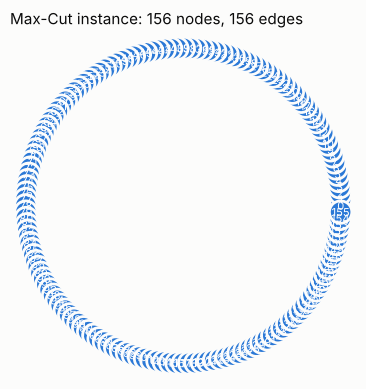

In [4]:
# ---------------------------------------------------------------------------------
# Section 4 - Build and validate the Max-Cut instance, compute the classical reference
# ---------------------------------------------------------------------------------
if not isinstance(N_QUBITS, (int, np.integer)) or N_QUBITS < 2:
    raise ValueError("N_QUBITS (number of nodes) must be an integer >= 2.")
N_QUBITS = int(N_QUBITS)
graph_kind = str(GRAPH).strip().lower()
if graph_kind == "example":
    graph_rng = np.random.default_rng(SEED)                        # reproducible random graph
    edges = [(i, j, 1.0) for i in range(N_QUBITS) for j in range(i + 1, N_QUBITS)
             if graph_rng.random() < EDGE_PROBABILITY]
elif graph_kind == "ring":
    edges = [(i, (i + 1) % N_QUBITS, 1.0) for i in range(N_QUBITS)] if N_QUBITS > 2 else [(0, 1, 1.0)]
elif graph_kind == "complete":
    edges = [(i, j, 1.0) for i in range(N_QUBITS) for j in range(i + 1, N_QUBITS)]
elif graph_kind == "custom":
    edges = [(int(e[0]), int(e[1]), float(e[2]) if len(e) > 2 else 1.0) for e in CUSTOM_EDGES]
else:
    raise ValueError("GRAPH must be 'example', 'ring', 'complete' or 'custom'.")
if not edges:
    raise ValueError("The graph has no edges - increase EDGE_PROBABILITY or provide CUSTOM_EDGES.")
for i, j, w in edges:
    if not (0 <= i < N_QUBITS and 0 <= j < N_QUBITS) or i == j:
        raise ValueError(f"Invalid edge ({i}, {j}): nodes must be distinct and in 0..{N_QUBITS - 1}.")
edge_i = [e[0] for e in edges]                                     # kernel arguments: first node of each edge
edge_j = [e[1] for e in edges]                                     # second node of each edge
edge_w = [e[2] for e in edges]                                     # weight of each edge
total_weight = float(sum(edge_w))                                  # W: random split has <C> = W/2

def cut_value(bitstring):
    """C(z) for a bitstring z (character i = group of node i)."""
    return sum(w for i, j, w in edges if bitstring[i] != bitstring[j])

def brute_force_maxcut():
    """Exact optimum by evaluating all 2^N splits with vectorised NumPy (node 0 = most significant bit)."""
    index = np.arange(2 ** N_QUBITS, dtype=np.int64)
    values = np.zeros(2 ** N_QUBITS)
    for i, j, w in edges:
        values += w * (((index >> (N_QUBITS - 1 - i)) ^ (index >> (N_QUBITS - 1 - j))) & 1)
    best = values.max()
    optimal = [format(int(z), f"0{N_QUBITS}b") for z in np.flatnonzero(np.isclose(values, best))]
    return best, optimal

def local_search_maxcut(restarts=200, seed=SEED):
    """Heuristic for large graphs: greedy single-node flips from random starts (NOT guaranteed optimal)."""
    rng = np.random.default_rng(seed)
    best_value, best_z = -np.inf, None
    for _ in range(restarts):
        z = list(rng.integers(0, 2, N_QUBITS).astype(str))
        improved = True
        while improved:
            improved = False
            for node in range(N_QUBITS):
                before = cut_value("".join(z))
                z[node] = "1" if z[node] == "0" else "0"
                if cut_value("".join(z)) > before:
                    improved = True
                else:
                    z[node] = "1" if z[node] == "0" else "0"     # undo the flip
        value = cut_value("".join(z))
        if value > best_value:
            best_value, best_z = value, "".join(z)
    return best_value, [best_z]

t0 = time.perf_counter()
if N_QUBITS <= BRUTE_FORCE_MAX_NODES:
    max_cut, optimal_bitstrings = brute_force_maxcut()
    reference_kind = "exact (brute force over all 2^N splits)"
else:
    max_cut, optimal_bitstrings = local_search_maxcut()
    reference_kind = "heuristic local search (best known, NOT guaranteed optimal)"
classical_time = time.perf_counter() - t0

print(f"Nodes (qubits)        : {N_QUBITS}")
print(f"Edges                 : {len(edges)}  (total weight W = {total_weight:g})")
print(f"Random-split baseline : <C> = W/2 = {total_weight / 2:g}")
print(f"Classical reference   : max cut = {max_cut:g}  [{reference_kind}, {classical_time:.2f} s]")
print(f"Optimal splits        : {len(optimal_bitstrings)} (e.g. {optimal_bitstrings[0]})")

def draw_graph(ax, split=None, title="Graph"):
    """Nodes on a circle; with a split: blue/orange groups, cut edges dark, uncut edges light."""
    angle = 2 * np.pi * np.arange(N_QUBITS) / N_QUBITS
    pos = np.c_[np.cos(angle), np.sin(angle)]
    for i, j, w in edges:
        is_cut = split is not None and split[i] != split[j]
        ax.plot(*pos[[i, j]].T, color=INK_SECONDARY if is_cut or split is None else GRID_COLOR,
                linewidth=1.6 if is_cut else 1.0, zorder=1)
    node_colors = [BLUE if split is None or split[k] == "0" else ORANGE for k in range(N_QUBITS)]
    ax.scatter(pos[:, 0], pos[:, 1], s=260, c=node_colors, edgecolors=SURFACE, linewidths=2, zorder=2)
    for k in range(N_QUBITS):
        ax.text(*pos[k], str(k), ha="center", va="center", fontsize=8, color="white", zorder=3)
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, loc="left")
    if split is not None:                                          # legend: node groups and cut edges
        handles = [matplotlib.lines.Line2D([], [], marker="o", linestyle="", color=BLUE, markersize=8, label="group 0"),
                   matplotlib.lines.Line2D([], [], marker="o", linestyle="", color=ORANGE, markersize=8, label="group 1"),
                   matplotlib.lines.Line2D([], [], color=INK_SECONDARY, linewidth=1.6, label="cut edge"),
                   matplotlib.lines.Line2D([], [], color=GRID_COLOR, linewidth=1.0, label="uncut edge")]
        ax.legend(handles=handles, loc="upper center", bbox_to_anchor=(0.5, 0.0), ncol=2, fontsize=7)

fig, ax = plt.subplots(figsize=(4.5, 4.5))
draw_graph(ax, title=f"Max-Cut instance: {N_QUBITS} nodes, {len(edges)} edges")
plt.show()

---
## Section 5 - Benchmark utilities and backend initialization

The first cell below defines helper functions shared by all eight notebooks (you do not need to edit it):

* **Backend selection** - translates `BACKEND` + `SIMULATION_METHOD` into a real CUDA-Q target and
  refuses combinations CUDA-Q does not support (for example MPS on a CPU) with an explanation.
* **Memory estimation** - exact formulas for the memory needed by the quantum state.
* **Live memory monitor** - a small separate process samples host RAM (`psutil`) and the memory of
  every NVIDIA GPU (NVML) while the execution cell runs.
* **Timing** - separates circuit construction, compilation and execution using CUDA-Q's built-in tracer.
* **Circuit drawing / export** and the **final benchmark report**.

The second cell activates the selected backend and checks that the problem fits into memory.

| Your choice | CUDA-Q target used | Notes |
|---|---|---|
| `cpu` + `statevector` | `qpp-cpu` | OpenMP state vector, fp64 |
| `cpu` + `density_matrix` | `density-matrix-cpu` | mixed states and noise, fp64, 4^N memory |
| `cpu` + `stabilizer` | `stim` | Clifford circuits + Pauli noise only (noise notebook) |
| `gpu` + `statevector` | `nvidia` (option fp32/fp64) | cuStateVec, one GPU |
| `gpu` + `trajectory` | `nvidia` + noise model | Monte-Carlo noise trajectories (noise notebook) |
| `gpu` + `mps` | `tensornet-mps` | cuTensorNet matrix product state |
| `gpu` + `tensornet` | `tensornet` | cuTensorNet exact contraction |
| `multi-gpu` + `statevector` | `nvidia` (option `mgpu,fp64`) | state vector split over GPUs; needs `mpiexec` |
| `multi-gpu` + `tensornet` | `tensornet` | contraction distributed over GPUs; needs `mpiexec` |
| `hardware` | provider target (`quantinuum`, `ionq`, ...) | sampling only; `emulate=True` runs locally |

In [5]:
# =====================================================================================
# BENCHMARK & MONITORING UTILITIES  (this cell is identical in all 8 notebooks)
# -------------------------------------------------------------------------------------
# You do not need to edit this cell. It defines helper functions used later:
#   resolve_backend()       -> turns BACKEND + SIMULATION_METHOD into a real CUDA-Q target
#   initialize_backend()    -> calls cudaq.set_target() safely
#   estimate_memory_bytes() -> memory needed to store the quantum state (exact formulas)
#   check_memory()          -> compares that requirement with free RAM / GPU memory
#   MemoryMonitor           -> live RAM + GPU memory monitoring during execution
#   profile_first_launch()  -> splits a kernel launch into construction/compilation/execution
#   measure_gate_time()     -> short calibration used for execution-time estimates
#   show_circuit()          -> prints a <=10-qubit circuit drawing and exports it
#   circuit_statistics()    -> gate counts/depth of the FULL circuit (no simulation needed)
#   show_report()           -> prints and saves the final benchmark report
# =====================================================================================

# ---------------------------------------------------------------------------------
# 1. Backend selection
# ---------------------------------------------------------------------------------
# (device, simulation method) -> (CUDA-Q target name, does the target accept fp32/fp64?)
# Only combinations that CUDA-Q actually ships are listed. Anything else raises a clear
# error instead of silently running on a different simulator.
_TARGET_TABLE = {
    ("cpu", "statevector"): ("qpp-cpu", False),             # OpenMP state vector (always fp64)
    ("cpu", "density_matrix"): ("density-matrix-cpu", False),  # exact mixed states (noise), fp64
    ("cpu", "stabilizer"): ("stim", False),                 # Clifford circuits + Pauli noise only
    ("gpu", "statevector"): ("nvidia", True),               # cuStateVec on one GPU
    ("gpu", "trajectory"): ("nvidia", True),                # cuStateVec + noise = Monte-Carlo trajectories
    ("gpu", "mps"): ("tensornet-mps", True),                # cuTensorNet matrix product state
    ("gpu", "tensornet"): ("tensornet", True),              # cuTensorNet exact tensor-network contraction
    ("multi-gpu", "statevector"): ("nvidia", True),         # one state vector split across GPUs (MPI)
    ("multi-gpu", "tensornet"): ("tensornet", True),        # contraction distributed across GPUs (MPI)
}

# Explanations for combinations CUDA-Q does not support (shown to the user on error).
_UNSUPPORTED_HINTS = {
    ("cpu", "mps"): "CUDA-Q's MPS simulator (target 'tensornet-mps') needs an NVIDIA GPU. "
                    "Use BACKEND='gpu', or SIMULATION_METHOD='statevector' on CPU.",
    ("cpu", "tensornet"): "CUDA-Q's tensor-network simulator (target 'tensornet') needs an NVIDIA GPU.",
    ("cpu", "trajectory"): "Trajectory-based noisy simulation runs on GPUs in CUDA-Q. On CPU use "
                           "'density_matrix' (exact, small N) or 'stabilizer' (Clifford circuits).",
    ("gpu", "density_matrix"): "CUDA-Q's density-matrix simulator is CPU-only ('density-matrix-cpu'). "
                               "On GPUs noisy circuits are simulated with 'trajectory'.",
    ("gpu", "stabilizer"): "The stabilizer simulator ('stim') is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "mps"): "The MPS simulator runs on a single GPU. Use BACKEND='gpu'.",
    ("multi-gpu", "density_matrix"): "The density-matrix simulator is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "stabilizer"): "The stabilizer simulator ('stim') is CPU-only. Use BACKEND='cpu'.",
    ("multi-gpu", "trajectory"): "Use BACKEND='gpu' for trajectory simulation in this notebook.",
}


def mpi_rank_info():
    """Return (rank, number_of_ranks). (0, 1) means a normal single-process run."""
    try:
        if cudaq.mpi.is_initialized():                       # CUDA-Q already started MPI
            return cudaq.mpi.rank(), cudaq.mpi.num_ranks()
    except Exception:                                        # cudaq.mpi may be unavailable
        pass
    # Common launcher environment variables (Open MPI, MPICH/Intel MPI, Slurm)
    for rank_var, size_var in (("OMPI_COMM_WORLD_RANK", "OMPI_COMM_WORLD_SIZE"),
                               ("PMI_RANK", "PMI_SIZE"), ("SLURM_PROCID", "SLURM_NTASKS")):
        if rank_var in os.environ:
            return int(os.environ[rank_var]), int(os.environ.get(size_var, "1"))
    return 0, 1


def resolve_backend(backend, method, precision, allowed_methods, hardware_provider=None,
                    hardware_emulate=True, hardware_machine=None):
    """Translate the user's BACKEND / SIMULATION_METHOD choice into a concrete CUDA-Q target.

    Nothing is changed in CUDA-Q here; we only validate and describe the choice.
    Raises ValueError / RuntimeError with an explanation for unsupported choices.
    """
    backend = str(backend).strip().lower()                   # tolerate "GPU", " cpu " ...
    requested = backend                                      # remember the user's original choice
    method = str(method).strip().lower()
    precision = str(precision).strip().lower()
    num_gpus = cudaq.num_available_gpus()                    # GPUs visible to CUDA-Q (0 on CPU-only machines)

    if backend == "auto":                                    # "auto": use a GPU if present, else the CPU
        backend = "gpu" if num_gpus > 0 else "cpu"
    if backend not in ("cpu", "gpu", "multi-gpu", "hardware"):
        raise ValueError(f"BACKEND must be 'auto', 'cpu', 'gpu', 'multi-gpu' or 'hardware', got {backend!r}")
    if precision not in ("fp32", "fp64"):
        raise ValueError(f"GPU_PRECISION must be 'fp32' or 'fp64', got {precision!r}")

    if backend == "hardware":                                # real QPU (or its local emulator)
        provider = str(hardware_provider).strip().lower()
        if not cudaq.has_target(provider):
            raise ValueError(f"CUDA-Q has no target named {provider!r}. "
                             f"Available targets: {sorted(t.name for t in cudaq.get_targets())}")
        kwargs = {}
        if hardware_emulate:
            kwargs["emulate"] = True                         # run locally, no credentials, no cost
        if hardware_machine:
            kwargs["machine"] = hardware_machine             # e.g. "H2-1E" for Quantinuum
        return {"backend_requested": requested, "device": "hardware", "method": "hardware",
                "target": provider, "kwargs": kwargs, "precision": "n/a", "num_gpus": num_gpus,
                "description": f"{provider} QPU " + ("(LOCAL EMULATION - no credentials, no cost)"
                                                     if hardware_emulate else "(REAL HARDWARE - needs credentials, may cost money)")}

    if method not in allowed_methods:                        # notebook-specific restriction
        raise ValueError(f"SIMULATION_METHOD={method!r} is not supported by this notebook. "
                         f"Choose one of {allowed_methods}.")
    if backend in ("gpu", "multi-gpu") and num_gpus == 0:    # never touch GPU targets without a GPU
        raise RuntimeError(f"BACKEND={backend!r} was requested but CUDA-Q sees no NVIDIA GPU "
                           "(cudaq.num_available_gpus() == 0). Check `nvidia-smi`, the driver and "
                           "the CUDA-Q CUDA variant (see README), or use BACKEND='cpu'.")
    key = (backend, method)
    if key not in _TARGET_TABLE:
        raise ValueError(_UNSUPPORTED_HINTS.get(key, f"Combination {key} is not supported by CUDA-Q."))
    target, takes_precision = _TARGET_TABLE[key]

    rank, size = mpi_rank_info()
    note = ""
    if backend == "multi-gpu" and method == "statevector":
        if size > 1:                                         # launched with mpiexec -> pool all GPUs
            option = f"mgpu,{precision}"
        else:                                                # plain Jupyter process: one rank = one GPU
            option = precision
            note = ("Multi-GPU state-vector pooling needs one MPI rank per GPU (see README: "
                    "`mpiexec -np <GPUs> python notebook.py`). This single process uses ONE GPU.")
    else:
        option = precision if takes_precision else ""
    kwargs = {"option": option} if option else {}
    return {"backend_requested": requested, "device": backend, "method": method, "target": target,
            "kwargs": kwargs, "precision": precision if takes_precision else "fp64",
            "num_gpus": num_gpus, "mpi_ranks": size,
            "description": f"{target}" + (f" (option={option})" if option else "") + (f" - {note}" if note else "")}


def initialize_backend(cfg, seed=None):
    """Activate the CUDA-Q target described by cfg (from resolve_backend) and seed its RNG."""
    if cfg["device"] == "multi-gpu" and cfg.get("mpi_ranks", 1) > 1 and not cudaq.mpi.is_initialized():
        cudaq.mpi.initialize()                               # required before using MPI-based targets
    cudaq.set_target(cfg["target"], **cfg["kwargs"])         # switch simulator / QPU
    if seed is not None:
        cudaq.set_random_seed(int(seed))                     # reproducible shot sampling
    return cudaq.get_target()


# ---------------------------------------------------------------------------------
# 2. Memory requirement estimates and availability checks
# ---------------------------------------------------------------------------------
def format_bytes(num_bytes):
    """Human-readable size. Works for astronomically large Python integers as well."""
    if num_bytes is None:
        return "n/a"
    if num_bytes >= 10**18:                                  # beyond exabytes: use powers of ten
        return f"10^{math.log10(num_bytes):.1f} bytes"
    for unit, scale in (("TB", 1e12), ("GB", 1e9), ("MB", 1e6), ("KB", 1e3)):
        if num_bytes >= scale:
            return f"{num_bytes / scale:.2f} {unit}"
    return f"{int(num_bytes)} B"


def estimate_memory_bytes(n_qubits, method, precision="fp64"):
    """Bytes needed to STORE the simulated quantum state (simulator workspace not included).

    statevector / trajectory : 2^N complex amplitudes (8 B each in fp32, 16 B in fp64)
    density_matrix           : 4^N complex entries (16 B each, fp64)
    mps                      : upper bound N * 2 * chi^2 amplitudes, chi = CUDAQ_MPS_MAX_BOND (default 64)
    stabilizer               : ~2N^2 bits (tiny)
    tensornet / hardware     : not predictable -> None
    """
    bytes_per_amplitude = 8 if precision == "fp32" else 16
    if method in ("statevector", "trajectory"):
        return (2 ** n_qubits) * bytes_per_amplitude
    if method == "density_matrix":
        return (4 ** n_qubits) * 16
    if method == "mps":
        chi = int(os.environ.get("CUDAQ_MPS_MAX_BOND", "64"))
        return n_qubits * 2 * chi * chi * bytes_per_amplitude
    if method == "stabilizer":
        return max(1, (2 * n_qubits * n_qubits) // 8)
    return None


def _nvml_gpu_memory():
    """List of (used_bytes, total_bytes, name) per GPU, or (None, reason) if NVML is unavailable."""
    if not HAVE_NVML:
        return None, "nvidia-ml-py (pynvml) is not installed"
    try:
        pynvml.nvmlInit()
        result = []
        for i in range(pynvml.nvmlDeviceGetCount()):
            handle = pynvml.nvmlDeviceGetHandleByIndex(i)
            info = pynvml.nvmlDeviceGetMemoryInfo(handle)
            name = pynvml.nvmlDeviceGetName(handle)
            result.append((info.used, info.total, name.decode() if isinstance(name, bytes) else name))
        return result, "NVML OK"
    except Exception as exc:                                 # no driver / no GPU
        return None, f"NVML unavailable ({type(exc).__name__}: {exc})"


def check_memory(required_bytes, cfg, safety_fraction=0.8, extra_copies=0):
    """Print required vs available memory and stop (MemoryError) if the run cannot fit.

    extra_copies: additional full copies of the state the notebook makes (e.g. get_state()
    returns a host copy of the state vector), added on top of the simulator's own copy.
    """
    if required_bytes is None:
        print("Memory requirement: cannot be predicted for this method (depends on circuit structure).")
        return None
    host_copy = extra_copies * required_bytes
    if cfg["device"] in ("gpu", "multi-gpu"):
        gpus, status = _nvml_gpu_memory()
        if gpus is None:
            print(f"GPU memory check skipped: {status}. Required (state only): {format_bytes(required_bytes)}")
            return None
        used_gpus = gpus if (cfg["device"] == "multi-gpu" and cfg.get("mpi_ranks", 1) > 1) else gpus[:1]
        available = sum(total - used for used, total, _ in used_gpus)
        where = f"free memory on {len(used_gpus)} GPU(s)"
    else:                                                    # CPU simulators and local emulators use host RAM
        available = psutil.virtual_memory().available
        where = "available host RAM"
        required_bytes = required_bytes + host_copy
        host_copy = 0
    print(f"Estimated memory for the quantum state : {format_bytes(required_bytes)}")
    if host_copy:
        print(f"Extra host RAM for state copies        : {format_bytes(host_copy)}")
    print(f"{where:<39}: {format_bytes(available)}  (safety limit {safety_fraction:.0%})")
    if required_bytes > safety_fraction * available:
        raise MemoryError(f"The state needs {format_bytes(required_bytes)} but only "
                          f"{format_bytes(available)} is {where.split(' on ')[0]} (limit {safety_fraction:.0%}). "
                          "Reduce the number of qubits, use fp32, an MPS/tensor-network method, more GPUs, "
                          "or raise MEMORY_SAFETY_FRACTION if you know the run fits.")
    print("Memory check: OK - the state fits within the safety limit.")
    return available


# ---------------------------------------------------------------------------------
# 3. Live memory monitor
# ---------------------------------------------------------------------------------
# Some CUDA-Q calls (for example cudaq.get_state) hold Python's global interpreter lock,
# which would freeze an ordinary Python thread. The sampler therefore runs as a small
# separate process that writes one JSON line per sample to a temporary file. A light
# thread in this notebook reads that file and refreshes the live display.
_SAMPLER_SCRIPT = r'''
import json, sys, time, psutil
pid, interval, path = int(sys.argv[1]), float(sys.argv[2]), sys.argv[3]
handles, pynvml = [], None
try:
    import pynvml
    pynvml.nvmlInit()
    handles = [pynvml.nvmlDeviceGetHandleByIndex(i) for i in range(pynvml.nvmlDeviceGetCount())]
except Exception:
    handles = []
proc = psutil.Process(pid)
with open(path, "a", buffering=1) as out:
    while True:
        try:
            rss = proc.memory_info().rss
        except psutil.Error:
            break
        vm = psutil.virtual_memory()
        gpu = []
        for h in handles:
            try:
                m = pynvml.nvmlDeviceGetMemoryInfo(h)
                gpu.append([m.used, m.total])
            except Exception:
                gpu.append([None, None])
        out.write(json.dumps({"t": time.time(), "rss": rss, "sys_used": vm.total - vm.available,
                              "sys_total": vm.total, "gpu": gpu}) + "\n")
        time.sleep(interval)
'''


class MemoryMonitor:
    """Samples host RAM (psutil) and per-GPU memory (NVML) while code runs.

    Usage:
        monitor = MemoryMonitor(interval_s=0.25, live=True)
        monitor.start()
        ... run quantum code ...
        summary = monitor.stop()
    """

    def __init__(self, interval_s=0.25, live=True, refresh_s=1.0):
        self.interval_s = max(0.05, float(interval_s))     # sampling period of the sampler process
        self.live = live                                    # refresh a one-line live display?
        self.refresh_s = max(0.2, float(refresh_s))         # display refresh period
        self.host = socket.gethostname()                    # node name (matters for multi-node runs)
        self.rank, self.nranks = mpi_rank_info()
        self.samples = []
        self.gpu_names = []
        gpus, self.gpu_status = _nvml_gpu_memory()
        if gpus:
            self.gpu_names = [name for _, _, name in gpus]
        self._proc = psutil.Process(os.getpid())

    def _sample_here(self):
        """One sample taken inside this process (used for baseline, final and fallback)."""
        vm = psutil.virtual_memory()
        gpus, _ = _nvml_gpu_memory()
        return {"t": time.time(), "rss": self._proc.memory_info().rss,
                "sys_used": vm.total - vm.available, "sys_total": vm.total,
                "gpu": [[u, t] for u, t, _ in gpus] if gpus else []}

    def _read_file_samples(self):
        try:
            with open(self._path) as fh:
                lines = fh.readlines()
        except OSError:
            return []
        parsed = []
        for line in lines:
            try:
                parsed.append(json.loads(line))
            except ValueError:                                # partially written last line
                pass
        return parsed

    def _format(self, sample, peak_rss, peak_sys):
        gb = 1e9
        text = (f"[{self.host} rank {self.rank}] t={sample['t'] - self._t0:6.1f}s | "
                f"RAM used {sample['sys_used'] / gb:6.2f}/{sample['sys_total'] / gb:.1f} GB "
                f"({100 * sample['sys_used'] / sample['sys_total']:4.1f}%, peak {peak_sys / gb:.2f}) | "
                f"process RSS {sample['rss'] / gb:5.2f} GB (peak {peak_rss / gb:.2f})")
        for i, (used, total) in enumerate(sample.get("gpu", [])):
            if used is not None:
                text += f" | GPU{i} {used / gb:5.2f}/{total / gb:.0f} GB ({100 * used / total:4.1f}%)"
        return text

    def _display_loop(self):
        while not self._stop_event.wait(self.refresh_s):
            samples = self._read_file_samples() if self._path else []
            if not samples:
                continue
            peak_rss = max(s["rss"] for s in samples)
            peak_sys = max(s["sys_used"] for s in samples)
            self._show(self._format(samples[-1], peak_rss, peak_sys))

    def _show(self, text):
        if self._handle is not None:
            self._handle.update(Pretty(text))               # update the same output line in Jupyter
        else:
            print(text, flush=True)                          # plain scripts: print a new line

    def start(self):
        self._t0 = time.time()
        self._stop_event = threading.Event()
        self._baseline = self._sample_here()
        fd, self._path = tempfile.mkstemp(prefix="cudaq_memmon_", suffix=".jsonl")
        os.close(fd)
        try:                                                 # preferred: independent sampler process
            self._sampler = subprocess.Popen(
                [sys.executable, "-c", _SAMPLER_SCRIPT, str(os.getpid()), str(self.interval_s), self._path],
                stdout=subprocess.DEVNULL, stderr=subprocess.DEVNULL)
            self.mode = "separate sampler process"
            deadline = time.time() + 5.0                     # wait for the first sample (<= 5 s)
            while time.time() < deadline and not self._read_file_samples():
                time.sleep(0.02)
        except Exception as exc:                              # fallback: in-process thread
            self._sampler = None
            self.mode = f"in-process thread (sampler process failed: {exc})"
            self._thread_sampler = threading.Thread(target=self._fallback_loop, daemon=True)
            self._thread_sampler.start()
        self._handle = None
        if self.live:
            if _IN_JUPYTER:
                self._handle = display(Pretty("starting live memory monitor ..."), display_id=True)
            self._display_thread = threading.Thread(target=self._display_loop, daemon=True)
            self._display_thread.start()
        return self

    def _fallback_loop(self):
        with open(self._path, "a", buffering=1) as out:
            while not self._stop_event.wait(self.interval_s):
                out.write(json.dumps(self._sample_here()) + "\n")

    def stop(self):
        final = self._sample_here()
        self._stop_event.set()
        if self._sampler is not None:
            self._sampler.terminate()
            try:
                self._sampler.wait(timeout=5)
            except subprocess.TimeoutExpired:
                self._sampler.kill()
        if self.live:
            self._display_thread.join(timeout=5)
        self.samples = [self._baseline] + self._read_file_samples() + [final]
        self.samples.sort(key=lambda s: s["t"])
        try:
            os.remove(self._path)
        except OSError:
            pass
        summary = self.summary()
        if self.live:
            self._show(self._format(final, summary["rss_peak_gb"] * 1e9, summary["ram_used_peak_gb"] * 1e9)
                       + "  <- monitoring finished")
        return summary

    def summary(self):
        """Baseline / peak values in GB and % for RAM, process RSS and every GPU."""
        gb = 1e9
        base = self.samples[0]
        result = {
            "node": self.host, "mpi_rank": self.rank, "mpi_ranks": self.nranks,
            "sampler": self.mode, "num_samples": len(self.samples),
            "duration_s": self.samples[-1]["t"] - self.samples[0]["t"],
            "ram_total_gb": base["sys_total"] / gb,
            "ram_used_baseline_gb": base["sys_used"] / gb,
            "ram_used_peak_gb": max(s["sys_used"] for s in self.samples) / gb,
            "rss_baseline_gb": base["rss"] / gb,
            "rss_peak_gb": max(s["rss"] for s in self.samples) / gb,
            "gpu_status": self.gpu_status, "gpus": [],
        }
        result["ram_used_peak_pct"] = 100 * result["ram_used_peak_gb"] / result["ram_total_gb"]
        num_gpus = max((len(s.get("gpu", [])) for s in self.samples), default=0)
        for i in range(num_gpus):
            used = [s["gpu"][i][0] for s in self.samples if len(s.get("gpu", [])) > i and s["gpu"][i][0] is not None]
            totals = [s["gpu"][i][1] for s in self.samples if len(s.get("gpu", [])) > i and s["gpu"][i][1]]
            if not used or not totals:
                continue
            result["gpus"].append({
                "index": i, "name": self.gpu_names[i] if i < len(self.gpu_names) else f"GPU{i}",
                "total_gb": totals[0] / gb, "used_baseline_gb": used[0] / gb, "used_peak_gb": max(used) / gb,
                "used_peak_pct": 100 * max(used) / totals[0]})
        return result

    def plot(self, ax=None, title="Memory during execution"):
        """Plot RAM, process RSS and per-GPU memory versus time."""
        if ax is None:
            _, ax = plt.subplots(figsize=(9, 3.2))
        t = np.array([s["t"] for s in self.samples]) - self.samples[0]["t"]
        ax.plot(t, [s["sys_used"] / 1e9 for s in self.samples], label="host RAM used (all processes)")
        ax.plot(t, [s["rss"] / 1e9 for s in self.samples], label="this notebook process (RSS)")
        num_gpus = max((len(s.get("gpu", [])) for s in self.samples), default=0)
        for i in range(num_gpus):
            pts = [(tt, s["gpu"][i][0] / 1e9) for tt, s in zip(t, self.samples)
                   if len(s.get("gpu", [])) > i and s["gpu"][i][0] is not None]
            if pts:
                ax.plot(*zip(*pts), label=f"GPU{i} memory used")
        ax.set_ylim(bottom=0)                                 # start at zero: do not exaggerate small changes
        ax.set_xlabel("time since start of execution [s]")
        ax.set_ylabel("memory [GB]")
        ax.set_title(title)
        ax.legend(fontsize=8, loc="best")
        ax.grid(alpha=0.3)
        return ax


def print_memory_summary(mem):
    """Print the memory section of the benchmark (per node and per GPU)."""
    print(f"Node {mem['node']} (MPI rank {mem['mpi_rank']}/{mem['mpi_ranks']}), sampler: {mem['sampler']}, "
          f"{mem['num_samples']} samples over {mem['duration_s']:.1f} s")
    print(f"  Host RAM used : baseline {mem['ram_used_baseline_gb']:.2f} GB -> peak {mem['ram_used_peak_gb']:.2f} GB "
          f"of {mem['ram_total_gb']:.1f} GB ({mem['ram_used_peak_pct']:.1f}%)")
    print(f"  Process RSS   : baseline {mem['rss_baseline_gb']:.2f} GB -> peak {mem['rss_peak_gb']:.2f} GB "
          f"(increase {mem['rss_peak_gb'] - mem['rss_baseline_gb']:+.2f} GB)")
    if mem["gpus"]:
        for g in mem["gpus"]:
            print(f"  GPU{g['index']} ({g['name']}): baseline {g['used_baseline_gb']:.2f} GB -> peak "
                  f"{g['used_peak_gb']:.2f} GB of {g['total_gb']:.1f} GB ({g['used_peak_pct']:.1f}%)")
    else:
        print(f"  GPU memory    : not monitored - {mem['gpu_status']}")
    if mem["mpi_ranks"] > 1:
        print("  (multi-node/multi-rank run: every MPI rank prints its own node's line)")


# ---------------------------------------------------------------------------------
# 4. Timing: construction vs compilation vs execution
# ---------------------------------------------------------------------------------
# CUDA-Q (>= 0.16) contains a span tracer that records how long each internal phase
# takes. We use it for the FIRST launch of a kernel only:
#   construction = Python source -> Quake IR      (span "PyKernelDecorator.compile")
#   compilation  = MLIR passes + LLVM JIT          (span "Compiler::runPassPipeline")
#   execution    = running the simulation/QPU job  (spans "streamlinedLaunchModule" and
#                  "...finalizeExecutionContext", where get_state() flushes queued gates)
# The tracer adds ~1 microsecond per gate, so later launches are timed without it.
_EXECUTION_SPANS = {"streamlinedLaunchModule", "DefaultPlatform::finalizeExecutionContext",
                    "BasicExecutionManager::finalizeExecutionContext"}


def _span_union_seconds(events, names):
    """Total time covered by spans with the given names (nested/overlapping spans counted once)."""
    intervals = sorted((e["ts"], e["ts"] + e["dur"]) for e in events if e.get("name") in names and "dur" in e)
    total, start, end = 0.0, None, None
    for s, e in intervals:
        if end is None or s > end:                            # a new, separate interval begins
            if end is not None:
                total += end - start
            start, end = s, e
        else:                                                 # overlapping/nested: extend
            end = max(end, e)
    if end is not None:
        total += end - start
    return total / 1e6                                        # tracer timestamps are microseconds


def profile_first_launch(launch):
    """Run launch() once under the CUDA-Q tracer. Returns (result, phase-times dict)."""
    tracer, backend_obj = None, None
    try:
        from cudaq.util import trace as tracer
        backend_obj = tracer.ChromeBackend()                  # in-memory event recorder
        tracer.set_backend(backend_obj)
    except Exception:                                         # older CUDA-Q: no tracer
        tracer = None
    t_start = time.perf_counter()
    try:
        result = launch()
    finally:
        wall = time.perf_counter() - t_start
        if tracer is not None:
            tracer.reset_backend()                            # stop recording
    phases = {"wall_s": wall, "construction_s": None, "compilation_s": None, "execution_s": None,
              "method": "wall clock only (tracer not available)"}
    if backend_obj is not None:
        events = json.loads(backend_obj.to_json()).get("traceEvents", [])
        construct = _span_union_seconds(events, {"cudaq.kernel.kernel_decorator.PyKernelDecorator.compile"})
        compile_ = _span_union_seconds(events, {"Compiler::runPassPipeline"})
        execute = _span_union_seconds(events, _EXECUTION_SPANS)
        if compile_ > 0 or execute > 0:
            phases.update(construction_s=construct, compilation_s=compile_, execution_s=execute,
                          method="CUDA-Q span tracer (first launch)")
        else:
            phases["method"] = "wall clock only (this target does not report compile/execute spans)"
    return result, phases


def fmt_seconds(value):
    return "not measured" if value is None else f"{value:.4f} s"


# ---------------------------------------------------------------------------------
# 5. Execution-time estimate: measure the cost of one gate on the active backend
# ---------------------------------------------------------------------------------
@cudaq.kernel
def _calibration_kernel(n: int, repetitions: int):
    qubits = cudaq.qvector(n)
    for _ in range(repetitions):
        for i in range(n):
            ry(0.1, qubits[i])
    mz(qubits)


def measure_gate_time(cfg, n_qubits):
    """Seconds per gate at n_qubits, measured on the active target (rough, +-3x).

    Two short runs with different gate counts are timed; their difference removes fixed
    overheads. If n_qubits is large, the calibration runs on fewer qubits and is scaled by
    2^dN (state vector) or 4^dN (density matrix) because cost grows with the state size.
    """
    method = cfg["method"]
    if cfg["device"] == "hardware":
        return None, "not estimated: hardware time is dominated by queueing and provider limits"
    if method in ("mps", "tensornet", "stabilizer"):
        return None, f"not estimated: '{method}' cost depends on entanglement/circuit structure"
    cap = 9 if method == "density_matrix" else (14 if cfg["device"] == "cpu" else 24)
    n_cal = max(2, min(n_qubits, cap))
    def timed(repetitions):
        start = time.perf_counter()
        cudaq.sample(_calibration_kernel, n_cal, repetitions, shots_count=1)
        return time.perf_counter() - start
    timed(1)                                                  # warm-up: JIT compilation
    r1, r2 = 2, 12
    t1 = min(timed(r1) for _ in range(2))
    t2 = min(timed(r2) for _ in range(2))
    per_gate = max((t2 - t1) / ((r2 - r1) * n_cal), 1e-9)
    growth = 4 if method == "density_matrix" else 2
    scaled = per_gate * growth ** (n_qubits - n_cal)
    detail = f"measured {per_gate * 1e3:.4f} ms/gate at {n_cal} qubits"
    if n_qubits > n_cal:
        detail += f", extrapolated x{growth}^{n_qubits - n_cal} to {n_qubits} qubits"
    return scaled, detail


def format_duration(seconds):
    if seconds is None:
        return "not estimated"
    if seconds < 1:
        return f"{seconds * 1e3:.0f} ms"
    if seconds < 120:
        return f"{seconds:.1f} s"
    if seconds < 7200:
        return f"{seconds / 60:.1f} min"
    if seconds < 3 * 86400:
        return f"{seconds / 3600:.1f} h"
    return f"{seconds / 86400:.1e} days"


# ---------------------------------------------------------------------------------
# 6. Circuit drawing, statistics and export
# ---------------------------------------------------------------------------------
def circuit_statistics(kernel, *args):
    """Gate counts and depth of the FULL circuit via cudaq.estimate_resources (no simulation)."""
    try:
        res = cudaq.estimate_resources(kernel, *args)
        by_type = dict(res.to_dict())
        measurements = sum(v for k, v in by_type.items() if k in ("mz", "mx", "my"))
        return {"qubits": res.num_qubits, "gates (excluding measurements)": res.count() - measurements,
                "measurements": measurements, "depth": res.depth,
                "multi-qubit gates": res.multi_qubit_gate_count, "gate counts by type": by_type}
    except Exception as exc:
        return {"error": f"estimate_resources failed: {type(exc).__name__}: {exc}"}


def _render_text_png(text, path):
    lines = text.splitlines() or [""]
    width, height = max(len(line) for line in lines), len(lines)
    fig_w, fig_h = max(4.0, 0.075 * width), max(1.0, 0.19 * height)
    dpi = int(min(150, 30000 / (fig_w * 1.0)))               # keep huge drawings below ~30k pixels
    fig = plt.figure(figsize=(fig_w, fig_h))
    fig.text(0.0, 1.0, text, family="DejaVu Sans Mono", fontsize=9, va="top", ha="left")
    fig.savefig(path, dpi=max(dpi, 30), bbox_inches="tight", facecolor="white")
    plt.close(fig)


def show_circuit(kernel, args, n_shown, n_full, title, export=False, formats=("txt", "png", "qir"),
                 out_dir="exports", basename="circuit", full_kernel=None, full_args=()):
    """Print the circuit drawing of `kernel(*args)` (built with n_shown <= 10 qubits) and export it.

    Export formats:
      "txt"  - the drawing as UTF-8 text          "png"  - the drawing as an image
      "qir"  - the FULL N-qubit circuit (full_kernel(*full_args)) as QIR, the LLVM-based
               intermediate representation CUDA-Q sends to simulators and QPUs
      "qasm" - the FULL circuit as OpenQASM 2.0 (only for circuits CUDA-Q can unroll into
               plain gates; otherwise skipped with an explanation)
    """
    drawing = cudaq.draw(kernel, *args)
    if n_full > n_shown:
        banner = (f"CIRCUIT VISUALIZATION EXAMPLE: {n_shown}-qubit version of the circuit. "
                  f"This is NOT the complete {n_full}-qubit circuit that will be executed.")
    else:
        banner = f"Circuit drawing ({n_shown} qubits). {title}"
    print("=" * min(len(banner), 110))
    print(banner)
    print("=" * min(len(banner), 110))
    print(drawing)
    saved = []
    if export:
        os.makedirs(out_dir, exist_ok=True)
        stem = os.path.join(out_dir, f"{basename}_{n_shown}q")
        if "txt" in formats:
            with open(stem + ".txt", "w", encoding="utf-8") as fh:
                fh.write(banner + "\n\n" + drawing)
            saved.append(stem + ".txt")
        if "png" in formats:
            try:
                _render_text_png(banner + "\n\n" + drawing, stem + ".png")
                saved.append(stem + ".png")
            except Exception as exc:
                print(f"PNG export skipped: {exc}")
        if "qir" in formats and full_kernel is not None:
            try:
                qir = cudaq.translate(full_kernel, *full_args, format="qir")
                if "translation failed" in qir:
                    raise RuntimeError("CUDA-Q could not translate this circuit to QIR")
                path = os.path.join(out_dir, f"{basename}_{n_full}q_full.ll")
                with open(path, "w") as fh:
                    fh.write(qir)
                saved.append(path)
            except Exception as exc:
                print(f"QIR export skipped: {type(exc).__name__}: {exc}")
        if "qasm" in formats and full_kernel is not None:
            try:
                specialised = cudaq.synthesize(full_kernel, *full_args) if full_args else full_kernel
                qasm = cudaq.translate(specialised, format="openqasm2")
                if "translation failed" in qasm:
                    raise RuntimeError("translation failed")
                path = os.path.join(out_dir, f"{basename}_{n_full}q_full.qasm")
                with open(path, "w") as fh:
                    fh.write(qasm)
                saved.append(path)
            except Exception as exc:
                print("OpenQASM 2.0 export skipped: CUDA-Q 0.16 can only emit OpenQASM for circuits that "
                      f"unroll into plain gates without sub-kernels or list arguments ({type(exc).__name__}). "
                      "Use the 'qir' export instead.")
        for path in saved:
            print(f"Exported: {path}")
    return drawing


# ---------------------------------------------------------------------------------
# 7. Final benchmark report
# ---------------------------------------------------------------------------------
def build_report(algorithm, cfg, n_qubits, shots, phases, mem, extra_times=None):
    """Collect the standard benchmark fields into an ordered dict."""
    target = cudaq.get_target()
    report = {
        "Algorithm": algorithm,
        "Date (UTC)": datetime.datetime.now(datetime.timezone.utc).strftime("%Y-%m-%d %H:%M:%S"),
        "CUDA-Q version": CUDAQ_VERSION,
        "Number of qubits": n_qubits,
        "Backend (requested -> used)": f"{cfg['backend_requested']} -> {cfg['device']}",
        "CUDA-Q target": target.name + (f" [{cfg['kwargs']}]" if cfg["kwargs"] else ""),
        "Simulation method": cfg["method"],
        "Numerical precision": cfg["precision"],
        "Number of shots": shots,
        "Circuit construction time": fmt_seconds(phases.get("construction_s")),
        "Compilation time (MLIR + JIT)": fmt_seconds(phases.get("compilation_s")),
        "Quantum execution time": fmt_seconds(phases.get("execution_s")),
    }
    for key, value in (extra_times or {}).items():
        report[key] = fmt_seconds(value)
    report["Total wall time of execution cell"] = fmt_seconds(phases.get("total_wall_s"))
    report["Timing method"] = phases.get("method", "")
    report["Peak host RAM used"] = f"{mem['ram_used_peak_gb']:.2f} GB ({mem['ram_used_peak_pct']:.1f}% of {mem['ram_total_gb']:.1f} GB)"
    report["Peak notebook process RSS"] = f"{mem['rss_peak_gb']:.2f} GB (baseline {mem['rss_baseline_gb']:.2f} GB)"
    if mem["gpus"]:
        for g in mem["gpus"]:
            report[f"Peak GPU{g['index']} memory ({g['name']})"] = (f"{g['used_peak_gb']:.2f} GB "
                                                                   f"({g['used_peak_pct']:.1f}% of {g['total_gb']:.1f} GB)")
    else:
        report["Peak GPU memory"] = f"not available - {mem['gpu_status']}"
    report["Node / MPI rank"] = f"{mem['node']} / rank {mem['mpi_rank']} of {mem['mpi_ranks']}"
    return report


def show_report(report, save=True, out_dir="exports", name="benchmark_report", figure=None):
    """Pretty-print the report and optionally save it as JSON (+ figure as PNG)."""
    width = max(len(str(k)) for k in report)
    print("=" * 100)
    print(f"{'FINAL BENCHMARK REPORT':^100}")
    print("=" * 100)
    for key, value in report.items():
        print(f"{str(key):<{width}} : {value}")
    print("=" * 100)
    if save:
        os.makedirs(out_dir, exist_ok=True)
        json_path = os.path.join(out_dir, f"{name}.json")
        with open(json_path, "w") as fh:
            json.dump({str(k): (v if isinstance(v, (int, float, str, bool, type(None))) else str(v))
                       for k, v in report.items()}, fh, indent=2)
        print(f"Report saved to {json_path}")
        if figure is not None:
            fig_path = os.path.join(out_dir, f"{name}.png")
            figure.savefig(fig_path, dpi=120, bbox_inches="tight")
            print(f"Final figure saved to {fig_path}")


def bit_reverse_order(vector, n_qubits):
    """Convert between CUDA-Q's state-vector order and 'qubit 0 = most significant bit'.

    cudaq.get_state() stores amplitude index i = sum_q b_q * 2^q (qubit 0 is the LEAST
    significant bit), while measured bitstrings are printed with qubit 0 FIRST (leftmost).
    Reversing the qubit axes converts one convention into the other (and back).
    """
    vector = np.asarray(vector)
    return vector.reshape([2] * n_qubits).transpose(list(range(n_qubits))[::-1]).reshape(-1)


print("Benchmark utilities loaded.")

Benchmark utilities loaded.


In [6]:
# ---------------------------------------------------------------------------------
# Activate the selected backend and print what is available on this machine
# ---------------------------------------------------------------------------------
ALLOWED_METHODS = ["statevector", "mps", "tensornet", "density_matrix"]   # simulation methods that make sense for this notebook
np.random.seed(SEED)                          # NumPy random numbers are reproducible too

backend_cfg = resolve_backend(BACKEND, SIMULATION_METHOD, GPU_PRECISION, ALLOWED_METHODS,
                              HARDWARE_PROVIDER, HARDWARE_EMULATE, HARDWARE_MACHINE)
active_target = initialize_backend(backend_cfg, seed=SEED)   # calls cudaq.set_target(...)

print(f"Requested backend : {BACKEND}  ->  device: {backend_cfg['device']}")
print(f"CUDA-Q target     : {active_target.name}  ({backend_cfg['description']})")
print(f"Simulation method : {backend_cfg['method']},  precision: {backend_cfg['precision']}")
print(f"GPUs visible      : {backend_cfg['num_gpus']},  CPU cores: {os.cpu_count()},  "
      f"host RAM: {psutil.virtual_memory().total / 1e9:.1f} GB")
gpu_list, gpu_status = _nvml_gpu_memory()
for i, (used, total, name) in enumerate(gpu_list or []):
    print(f"  GPU{i}: {name}, {total / 1e9:.1f} GB total, {used / 1e9:.2f} GB in use")
if not gpu_list:
    print(f"  GPU monitoring: {gpu_status}")

# Hardware targets estimate expectation values from shots; simulators can compute them exactly.
objective_shots = OBJECTIVE_SHOTS if OBJECTIVE_SHOTS is not None else (SHOTS if backend_cfg["device"] == "hardware" else None)
print(f"Objective evaluation  : {'exact expectation value' if objective_shots is None else f'{objective_shots} shots per evaluation'}")

Requested backend : hardware  ->  device: hardware
CUDA-Q target     : ibm  (ibm QPU (REAL HARDWARE - needs credentials, may cost money))
Simulation method : hardware,  precision: n/a
GPUs visible      : 0,  CPU cores: 4,  host RAM: 16.9 GB
  GPU monitoring: nvidia-ml-py (pynvml) is not installed
Objective evaluation  : 4000 shots per evaluation


---
## Section 6 - Expected output (before execution)

**Expected graphs (Section 9)**
1. *Objective convergence* - expected cut $\langle C\rangle$ versus optimizer evaluation, rising from the
   random-split value $W/2$ towards (but below) the maximum cut. A flat end means the optimizer converged.
2. *Bitstring distribution* - the most frequently measured splits with their cut values; optimal splits highlighted.
3. *Best split drawn on the graph* (cut edges dark) and the *memory timeline*.

**Expected numbers:** the brute-force optimum $C_{\max}$ (Section 4) is the target. Typical depth-2 QAOA results
on random graphs reach $r \approx 0.75-0.9$ - a typical range, not a guarantee. The best *sampled* split is often
optimal when the optimal splits receive enough probability (expected optimal hits = $P_{\text{opt}}\times$ `SHOTS`).

**Execution time and memory** - exact state memory and a calibrated (rough) time estimate are computed below.

In [7]:
# ---------------------------------------------------------------------------------
# Section 6 - Memory requirement and execution-time estimate
# ---------------------------------------------------------------------------------
state_bytes = estimate_memory_bytes(N_QUBITS, backend_cfg["method"], backend_cfg["precision"])
print("Expected memory")
check_memory(state_bytes, backend_cfg, MEMORY_SAFETY_FRACTION)

gates_per_circuit = N_QUBITS + QAOA_LAYERS * (3 * len(edges) + N_QUBITS)   # H layer + p * (3 gates/edge + RX layer)
seconds_per_gate, timing_note = measure_gate_time(backend_cfg, N_QUBITS)
evaluations = MAX_EVALUATIONS + 1                                   # optimizer budget + final sampling run
print("\nExpected execution time (ESTIMATE)")
print(f"  Gates per QAOA circuit : {gates_per_circuit:,} ({len(edges)} edges x 3 gates x {QAOA_LAYERS} layers + rotations)")
print(f"  Circuit evaluations    : up to {evaluations}")
print(f"  Calibration            : {timing_note}")
if seconds_per_gate is not None:
    print(f"  Estimated total        : ~{format_duration(evaluations * gates_per_circuit * seconds_per_gate)} "
          "(expectation values add a few % on simulators)")
print(f"\nTarget: maximum cut {max_cut:g}; random-split baseline {total_weight / 2:g}")

Expected memory
Memory requirement: cannot be predicted for this method (depends on circuit structure).

Expected execution time (ESTIMATE)
  Gates per QAOA circuit : 1,404 (156 edges x 3 gates x 2 layers + rotations)
  Circuit evaluations    : up to 7
  Calibration            : not estimated: hardware time is dominated by queueing and provider limits

Target: maximum cut 140; random-split baseline 78


---
## Section 7 - Quantum circuit generation

* `qaoa_state` - prepares $|\boldsymbol\gamma,\boldsymbol\beta\rangle$ (used by `cudaq.observe` during optimisation).
* `qaoa_sample` - the same circuit followed by measurement (used for the final bitstring distribution).
* `cost_hamiltonian` - $H_C = \sum_{(i,j)} \tfrac{w_{ij}}{2} Z_i Z_j$ as a CUDA-Q spin operator.

The angle vector is `params = [gamma_1 ... gamma_p, beta_1 ... beta_p]`.

In [8]:
# ---------------------------------------------------------------------------------
# Section 7a - CUDA-Q kernels and cost Hamiltonian for QAOA
# ---------------------------------------------------------------------------------
def build_qaoa_kernels():
    """Create and return fresh CUDA-Q kernels (called again in the execution cell)."""

    @cudaq.kernel
    def qaoa_state(n: int, edge_i: list[int], edge_j: list[int], weights: list[float],
                   layers: int, params: list[float]):
        """|gamma, beta> = prod_l exp(-i beta_l H_M) exp(-i gamma_l H_C) |+>^n."""
        qubits = cudaq.qvector(n)
        h(qubits)                                            # |+>^n: every split equally likely
        for layer in range(layers):
            gamma = params[layer]                            # cost angle of this layer
            beta = params[layers + layer]                    # mixer angle of this layer
            for e in range(len(edge_i)):                     # exp(-i gamma w/2 Z_i Z_j) for every edge
                x.ctrl(qubits[edge_i[e]], qubits[edge_j[e]])
                rz(gamma * weights[e], qubits[edge_j[e]])    # RZ(t) = exp(-i t Z/2) -> phase depends on z_i XOR z_j
                x.ctrl(qubits[edge_i[e]], qubits[edge_j[e]])
            for q in range(n):
                rx(2.0 * beta, qubits[q])                    # mixer exp(-i beta X) moves probability between splits

    @cudaq.kernel
    def qaoa_sample(n: int, edge_i: list[int], edge_j: list[int], weights: list[float],
                    layers: int, params: list[float]):
        """Same circuit, then measure every qubit (bit i = group of node i)."""
        qubits = cudaq.qvector(n)
        h(qubits)
        for layer in range(layers):
            gamma = params[layer]
            beta = params[layers + layer]
            for e in range(len(edge_i)):
                x.ctrl(qubits[edge_i[e]], qubits[edge_j[e]])
                rz(gamma * weights[e], qubits[edge_j[e]])
                x.ctrl(qubits[edge_i[e]], qubits[edge_j[e]])
            for q in range(n):
                rx(2.0 * beta, qubits[q])
        mz(qubits)

    return {"state": qaoa_state, "sample": qaoa_sample}


def cost_hamiltonian():
    """H_C = sum_(i,j) w_ij/2 Z_i Z_j  (maximising the cut <=> minimising <H_C>)."""
    hamiltonian = None
    for i, j, w in edges:
        term = 0.5 * w * cudaq.spin.z(i) * cudaq.spin.z(j)       # one Z_i Z_j term per edge
        hamiltonian = term if hamiltonian is None else hamiltonian + term
    return hamiltonian


if isinstance(INITIAL_PARAMETERS, str) and INITIAL_PARAMETERS.strip().lower() == "ramp":
    initial_params = np.concatenate([np.linspace(0.2, 0.6, QAOA_LAYERS),        # gamma_1 .. gamma_p rising
                                     np.linspace(0.6, 0.2, QAOA_LAYERS)])       # beta_1 .. beta_p falling
else:
    initial_params = np.asarray(INITIAL_PARAMETERS, dtype=float)
    if initial_params.size != 2 * QAOA_LAYERS:
        raise ValueError(f"INITIAL_PARAMETERS needs 2 * QAOA_LAYERS = {2 * QAOA_LAYERS} numbers.")
H_C = cost_hamiltonian()
kernels_vis = build_qaoa_kernels()
print(f"Cost Hamiltonian: {H_C.term_count} Z_iZ_j terms on {N_QUBITS} qubits")
print(f"Initial angles  : gamma = {np.round(initial_params[:QAOA_LAYERS], 3).tolist()}, "
      f"beta = {np.round(initial_params[QAOA_LAYERS:], 3).tolist()}")

Cost Hamiltonian: 156 Z_iZ_j terms on 156 qubits
Initial angles  : gamma = [0.2, 0.6], beta = [0.6, 0.2]


In [9]:
# ---------------------------------------------------------------------------------
# Section 7b - Circuit visualization (at most 10 qubits) and full-circuit statistics
# ---------------------------------------------------------------------------------
n_draw = min(int(DRAW_QUBITS), 10, N_QUBITS)
if not 0 < n_draw <= 10:
    raise ValueError("DRAW_QUBITS must be between 1 and 10.")
draw_edges = [(i, j, w) for i, j, w in edges if i < n_draw and j < n_draw]   # sub-graph on the first n_draw nodes
if not draw_edges:
    draw_edges = [(0, 1, 1.0)]
print(f"The drawing uses the sub-graph of the first {n_draw} nodes ({len(draw_edges)} edges) and ONE QAOA layer.")
show_circuit(kernels_vis["sample"],
             (n_draw, [e[0] for e in draw_edges], [e[1] for e in draw_edges], [e[2] for e in draw_edges],
              1, [float(initial_params[0]), float(initial_params[QAOA_LAYERS])]),
             n_draw, N_QUBITS, title="One QAOA layer.", export=EXPORT_CIRCUIT, formats=EXPORT_FORMATS,
             out_dir=EXPORT_DIR, basename="qaoa", full_kernel=kernels_vis["sample"],
             full_args=(N_QUBITS, edge_i, edge_j, edge_w, QAOA_LAYERS, initial_params.tolist()))
stats = circuit_statistics(kernels_vis["sample"], N_QUBITS, edge_i, edge_j, edge_w, QAOA_LAYERS, initial_params.tolist())
print(f"\nFULL circuit statistics ({N_QUBITS} qubits, p = {QAOA_LAYERS}):")
for key, value in stats.items():
    print(f"  {key:<32}: {value}")

The drawing uses the sub-graph of the first 10 nodes (9 edges) and ONE QAOA layer.


CIRCUIT VISUALIZATION EXAMPLE: 10-qubit version of the circuit. This is NOT the complete 156-qubit circuit that will be executed.
     ╭───╮                     ╭─────────╮                           »
q0 : ┤ h ├──●───────────────●──┤ rx(1.2) ├───────────────────────────»
     ├───┤╭─┴─╮╭─────────╮╭─┴─╮╰─────────╯                ╭─────────╮»
q1 : ┤ h ├┤ x ├┤ rz(0.2) ├┤ x ├─────●──────────────────●──┤ rx(1.2) ├»
     ├───┤╰───╯╰─────────╯╰───╯   ╭─┴─╮   ╭─────────╮╭─┴─╮╰─────────╯»
q2 : ┤ h ├────────────────────────┤ x ├───┤ rz(0.2) ├┤ x ├─────●─────»
     ├───┤                        ╰───╯   ╰─────────╯╰───╯   ╭─┴─╮   »
q3 : ┤ h ├───────────────────────────────────────────────────┤ x ├───»
     ├───┤                                                   ╰───╯   »
q4 : ┤ h ├───────────────────────────────────────────────────────────»
     ├───┤                                                           »
q5 : ┤ h ├───────────────────────────────────────────────────────────»
     ├───┤        

Exported: exports/qaoa_10q.txt
Exported: exports/qaoa_10q.png
Exported: exports/qaoa_156q_full.ll

FULL circuit statistics (156 qubits, p = 2):
  qubits                          : 156
  gates (excluding measurements)  : 1404
  measurements                    : 156
  depth                           : 940
  multi-qubit gates               : 624
  gate counts by type             : {'h': 156, 'cx': 624, 'rz': 312, 'rx': 312, 'mz': 156}


---
## Section 8 - Execution with live memory monitoring

Running the next cell:
1. initialises the selected backend,
2. builds the QAOA circuit (fresh kernels),
3. optimises the $2p$ angles (each evaluation = one `cudaq.observe` of $H_C$) and samples the optimised circuit
   with `SHOTS` shots,
4. monitors host RAM and GPU memory during the whole cell,
5. prints a short summary.

**How the timings are measured**

| Phase | What happens | How it is measured |
|---|---|---|
| Circuit construction | the Python kernel is translated into CUDA-Q's quantum IR (Quake/MLIR) | CUDA-Q tracer span on the first launch |
| Compilation | MLIR optimisation passes + LLVM just-in-time compilation to machine code | CUDA-Q tracer span on the first launch (cached afterwards) |
| Quantum execution | the simulator (or QPU) applies the gates and measures | tracer span on the first launch + wall-clock time of all later launches |

**How memory is monitored:** a separate lightweight process samples memory every `MEMORY_SAMPLE_INTERVAL_S`
seconds - host RAM used by all processes and this notebook's resident memory (RSS) with `psutil`, and the
memory of every NVIDIA GPU with NVML (device-wide, so it includes other processes on that GPU). Some CUDA-Q
calls (e.g. `cudaq.get_state`) hold Python's interpreter lock, so the *live line* may pause during them,
but the background sampler keeps recording, so the reported peaks are still captured. Peaks shorter than
the sampling interval can be missed. Nothing is estimated or invented: if a monitor is unavailable (e.g. no
NVIDIA driver), the report says so.

In [10]:
# =====================================================================================
# >>> EXECUTION CELL - QAOA optimisation + sampling with live memory monitoring <<<
# =====================================================================================
execution_ok, execution_error = False, None
history_cut, history_params = [], []                               # convergence record
phases, later_launch_time = None, 0.0
monitor = MemoryMonitor(MEMORY_SAMPLE_INTERVAL_S, live=LIVE_MEMORY_DISPLAY)
monitor.start()
cell_start = time.perf_counter()
try:
    # Step 1 - initialise the backend
    initialize_backend(backend_cfg, seed=SEED)
    # Step 2 - build the circuit (fresh kernels)
    kernels = build_qaoa_kernels()
    observe_kwargs = {} if objective_shots is None else {"shots_count": int(objective_shots)}

    def objective(params):
        """Minimise <H_C>; record the expected cut <C> = W/2 - <H_C> after every evaluation."""
        global phases, later_launch_time
        launch = lambda: cudaq.observe(kernels["state"], H_C, N_QUBITS, edge_i, edge_j, edge_w,
                                       QAOA_LAYERS, list(params), **observe_kwargs)
        if phases is None:                                           # first launch: traced timing breakdown
            result, phases = profile_first_launch(launch)
        else:
            t0 = time.perf_counter()
            result = launch()
            later_launch_time += time.perf_counter() - t0
        energy = result.expectation()
        history_cut.append(total_weight / 2 - energy)
        history_params.append(np.array(params, dtype=float))
        return energy

    # Step 3 - classical optimisation of the angles
    method = OPTIMIZER.strip()
    options = {"COBYLA": {"maxiter": MAX_EVALUATIONS, "rhobeg": 0.2}, "NELDER-MEAD": {"maxfev": MAX_EVALUATIONS},
               "POWELL": {"maxfev": MAX_EVALUATIONS}, "L-BFGS-B": {"maxfun": MAX_EVALUATIONS}}.get(method.upper())
    if options is None:
        raise ValueError("OPTIMIZER must be 'COBYLA', 'Nelder-Mead', 'Powell' or 'L-BFGS-B'.")
    optimisation_start = time.perf_counter()
    opt = minimize(objective, initial_params, method=method, options=options)
    optimisation_time = time.perf_counter() - optimisation_start
    best_index = int(np.argmax(history_cut))                        # best evaluated angles (not only the last)
    best_params = history_params[best_index]

    # Step 4 - sample the optimised circuit
    t0 = time.perf_counter()
    counts = cudaq.sample(kernels["sample"], N_QUBITS, edge_i, edge_j, edge_w, QAOA_LAYERS,
                          best_params.tolist(), shots_count=SHOTS)
    sampling_time = time.perf_counter() - t0
    execution_ok = True
except Exception as exc:
    execution_error = exc
    print(f"\nEXECUTION FAILED: {type(exc).__name__}: {exc}")
    print("Hints: reduce N_QUBITS or MAX_EVALUATIONS, choose another BACKEND / SIMULATION_METHOD (README).")
finally:
    memory = monitor.stop()
    total_wall = time.perf_counter() - cell_start

if execution_ok:
    phases["total_wall_s"] = total_wall
    expected_cut = history_cut[best_index]
    ratio = expected_cut / max_cut
    samples = sorted(((b, c, cut_value(b)) for b, c in counts.items()), key=lambda t: (-t[1], -t[2]))
    best_sample = max(samples, key=lambda t: (t[2], t[1]))
    optimal_set = set(optimal_bitstrings)
    optimal_hits = sum(c for b, c, v in samples if np.isclose(v, max_cut))
    print(f"\nOptimizer           : {method}, {len(history_cut)} evaluations, message: {opt.message}")
    print(f"Best expected cut   : <C> = {expected_cut:.4f}  ->  approximation ratio r = {ratio:.4f}")
    print(f"Best sampled split  : {best_sample[0]}  cut = {best_sample[2]:g}  (max cut {max_cut:g})")
    print(f"P(optimal split)    : {optimal_hits / SHOTS:.4f} ({optimal_hits} of {SHOTS} shots)")
    print(f"Timing              : first launch construction {fmt_seconds(phases['construction_s'])}, compilation "
          f"{fmt_seconds(phases['compilation_s'])}; optimisation {optimisation_time:.2f} s; sampling {sampling_time:.2f} s")
    print(f"Total cell wall time: {total_wall:.2f} s\n")
print_memory_summary(memory)

[ibm] reused finished job dbnlmi8qtr0c73ad9l50 from before the pause (4 QPU s)


[ibm] reused finished job dbnltvgou4as73b4q4fg from before the pause (4 QPU s)


[ibm] submitted job dbolhntt7fqc73881qjg (1 circuit(s), 4000 shots, 156-qubit chip ibm_marrakesh, account S.No 19)


[ibm] submitted job dbolr2oou4as73csadbg (1 circuit(s), 4000 shots, 156-qubit chip ibm_marrakesh, account S.No 19)


[ibm] submitted job dbolrb5t7fqc73882ca0 (1 circuit(s), 4000 shots, 156-qubit chip ibm_marrakesh, account S.No 19)


[ibm] submitted job dbolrgk4148s739t7p30 (1 circuit(s), 4000 shots, 156-qubit chip ibm_marrakesh, account S.No 19)



Optimizer           : COBYLA, 6 evaluations, message: Return from COBYLA because the objective function has been evaluated MAXFUN times.
Best expected cut   : <C> = 71.9765  ->  approximation ratio r = 0.5141
Best sampled split  : 101010000011000100101011010101000100011001100110100100001000000010110100010111101010101010110001110011010011101100010110011000110101100110001100101010010011  cut = 92  (max cut 140)
P(optimal split)    : 0.0000 (0 of 4000 shots)
Timing              : first launch construction not measured, compilation not measured; optimisation 1280.70 s; sampling 0.31 s
Total cell wall time: 1281.04 s

Node vm (MPI rank 0/1), sampler: separate sampler process, 5115 samples over 1281.1 s
  Host RAM used : baseline 2.23 GB -> peak 4.00 GB of 16.9 GB (23.7%)
  Process RSS   : baseline 0.27 GB -> peak 0.42 GB (increase +0.15 GB)
  GPU memory    : not monitored - nvidia-ml-py (pynvml) is not installed


---
## Section 9 - Results and visualization

The table lists the most frequently measured bitstrings (qubit/node 0 first) with their **objective value**
(cut size). Optimal splits are marked. A split and its complement (all bits flipped) describe the same cut.

rank  bitstring                                                                                                                                                     counts   prob.  cut C(z)  C/Cmax
   1  101010000011000100101011010101000100011001100110100100001000000010110100010111101010101010110001110011010011101100010110011000110101100110001100101010010011       1   0.000        92   0.657
   2  000000110101100111011001000001001011101000101010010100110000110010100101010001010001010010100111011001000011010101000000110110001010101000000010010101000011       1   0.000        92   0.657
   3  000001011001000101001001000010101000000011100100000000011010110010010110110000001011110100101110100101010010110010010100010101101101100100110101010001001010       1   0.000        92   0.657
   4  010001000000100110100000101110101101100111100101010011000101010001000010101101000111101101100001100101011010000010101010100100010110000010110101101110010010       1   0.000        92   0.657
   5  000011011

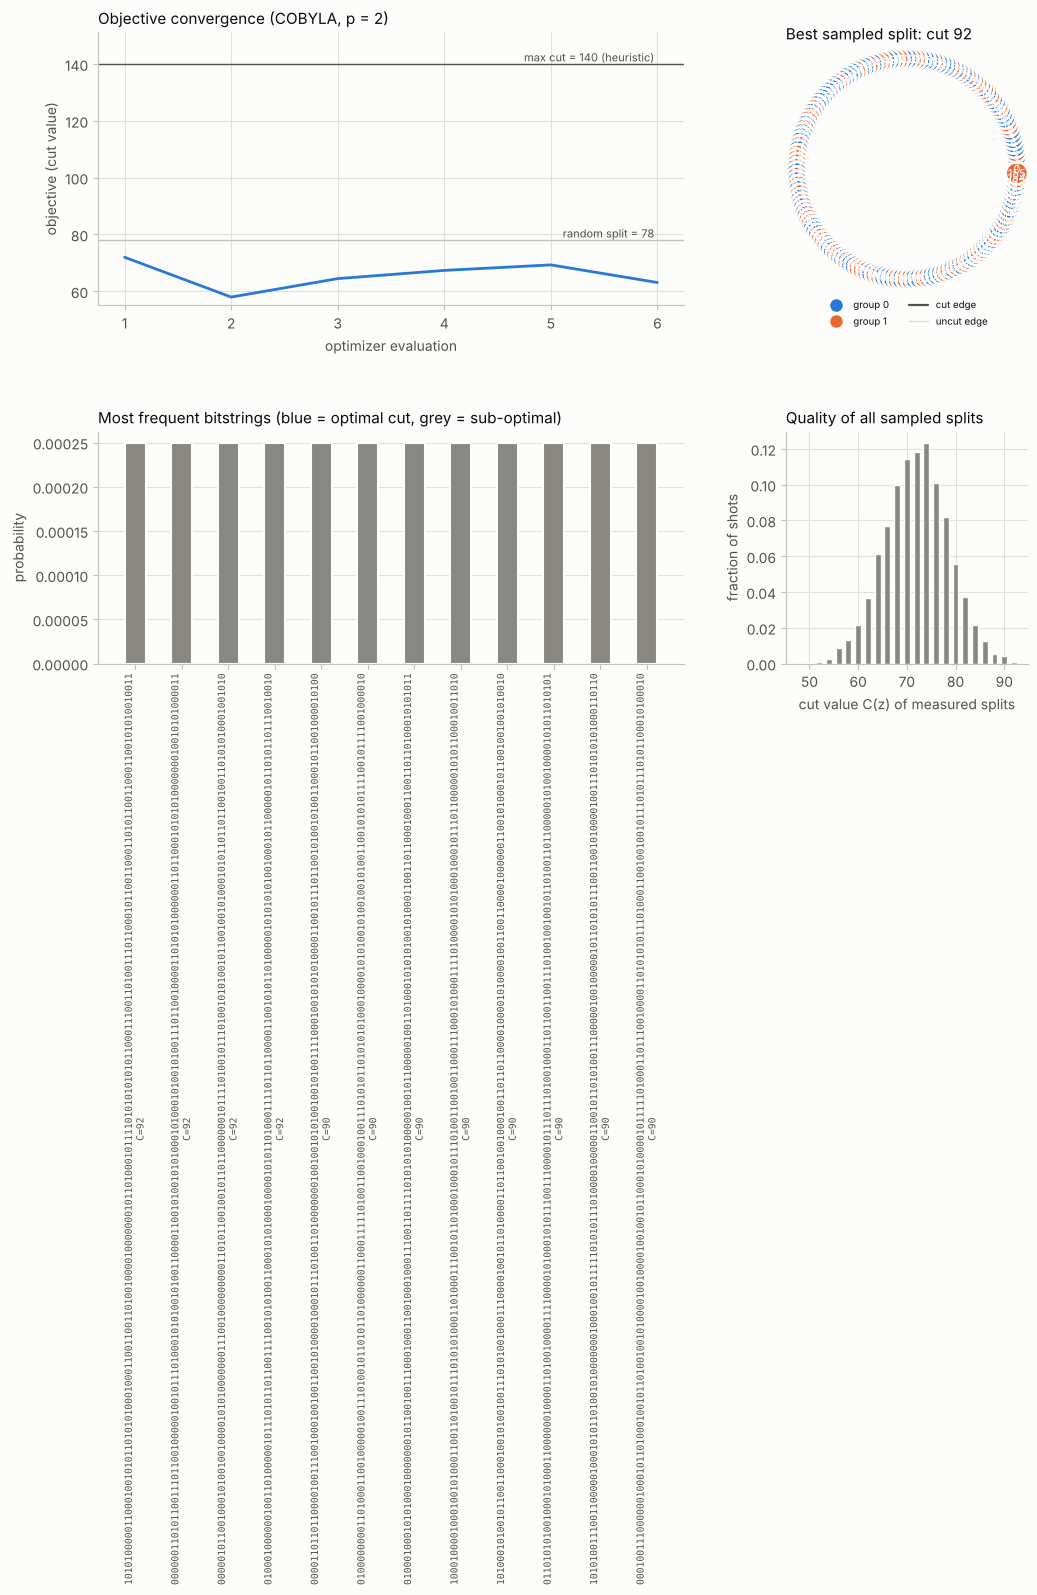

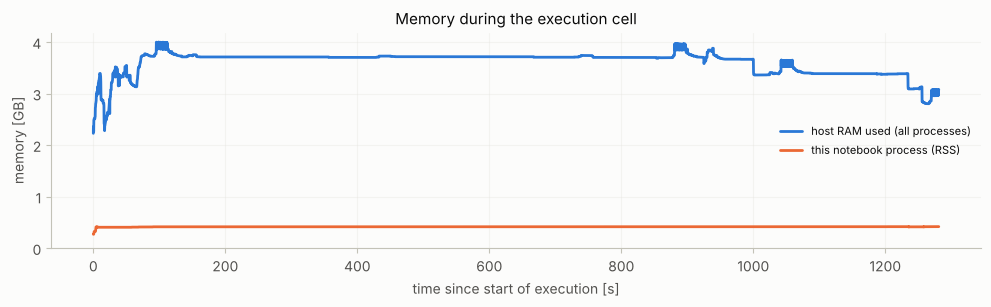

In [11]:
# ---------------------------------------------------------------------------------
# Section 9 - Measured bitstrings, objective values and plots
# ---------------------------------------------------------------------------------
if not execution_ok:
    print("Skipped: the execution cell failed (see the error message above).")
else:
    print(f"{'rank':>4}  {'bitstring':<{max(9, N_QUBITS)}}  {'counts':>6}  {'prob.':>6}  {'cut C(z)':>8}  {'C/Cmax':>6}")
    for rank, (b, c, v) in enumerate(samples[:TOP_BITSTRINGS], start=1):
        flag = "  <-- optimal" if np.isclose(v, max_cut) else ""
        print(f"{rank:>4}  {b:<{max(9, N_QUBITS)}}  {c:>6}  {c / SHOTS:>6.3f}  {v:>8g}  {v / max_cut:>6.3f}{flag}")
    cut_of_shots = np.repeat([v for _, _, v in samples], [c for _, c, _ in samples])
    print(f"\nMean cut over all {SHOTS} shots : {cut_of_shots.mean():.3f}   (expected <C> = {expected_cut:.3f}, random = {total_weight / 2:g})")

    fig = plt.figure(figsize=(12, 8.2))
    grid = fig.add_gridspec(2, 3, height_ratios=[1.0, 0.85], hspace=0.5, wspace=0.42)
    # (a) objective convergence
    ax_c = fig.add_subplot(grid[0, 0:2])
    ax_c.plot(np.arange(1, len(history_cut) + 1), history_cut, color=BLUE, label=r"expected cut $\langle C\rangle$")
    ax_c.axhline(max_cut, color=INK_SECONDARY, linewidth=1)
    ax_c.text(len(history_cut), max_cut, f"max cut = {max_cut:g} ({'exact' if N_QUBITS <= BRUTE_FORCE_MAX_NODES else 'heuristic'}) ",
              ha="right", va="bottom", fontsize=8, color=INK_SECONDARY)
    ax_c.axhline(total_weight / 2, color=AXIS_COLOR, linewidth=1)
    ax_c.text(len(history_cut), total_weight / 2, f"random split = {total_weight / 2:g} ", ha="right", va="bottom",
              fontsize=8, color=INK_SECONDARY)
    ax_c.set_xlabel("optimizer evaluation")
    ax_c.set_ylabel("objective (cut value)")
    ax_c.set_title(f"Objective convergence ({OPTIMIZER}, p = {QAOA_LAYERS})", loc="left")
    ax_c.set_ylim(min(history_cut + [total_weight / 2]) * 0.95, max_cut * 1.08)
    # (b) best split on the graph
    ax_g = fig.add_subplot(grid[0, 2])
    draw_graph(ax_g, split=best_sample[0], title=f"Best sampled split: cut {best_sample[2]:g}")
    # (c) bitstring distribution with objective values
    ax_b = fig.add_subplot(grid[1, 0:2])
    shown = samples[:TOP_BITSTRINGS]
    xpos = np.arange(len(shown))
    colors = [BLUE if np.isclose(v, max_cut) else INK_MUTED for _, _, v in shown]
    ax_b.bar(xpos, [c / SHOTS for _, c, _ in shown], width=0.45, color=colors, edgecolor=SURFACE, linewidth=1.5)
    ax_b.set_xticks(xpos, [f"{b}\nC={v:g}" for b, _, v in shown], rotation=90, fontsize=7, family="DejaVu Sans Mono")
    ax_b.set_ylabel("probability")
    ax_b.set_title("Most frequent bitstrings (blue = optimal cut, grey = sub-optimal)", loc="left")
    ax_b.grid(axis="x", visible=False)
    # (d) distribution of cut values over all shots
    ax_h = fig.add_subplot(grid[1, 2])
    values, freq = np.unique(cut_of_shots, return_counts=True)
    ax_h.bar(values, freq / SHOTS, width=0.6 * (np.min(np.diff(values)) if len(values) > 1 else 1.0),
             color=[BLUE if np.isclose(v, max_cut) else INK_MUTED for v in values], edgecolor=SURFACE)
    ax_h.set_xlabel("cut value C(z) of measured splits")
    ax_h.set_ylabel("fraction of shots")
    ax_h.set_title("Quality of all sampled splits", loc="left")
    plt.show()

    fig_m, ax_m = plt.subplots(figsize=(12, 2.8))
    monitor.plot(ax=ax_m, title="Memory during the execution cell")
    plt.show()

---
## Section 10 - Final benchmark report

                                       FINAL BENCHMARK REPORT                                       
Algorithm                             : QAOA (Max-Cut)
Date (UTC)                            : 2026-11-09 05:44:57
CUDA-Q version                        : 0.16.0
Number of qubits                      : 156
Backend (requested -> used)           : hardware -> hardware
CUDA-Q target                         : ibm
Simulation method                     : hardware
Numerical precision                   : n/a
Number of shots                       : 4000
Circuit construction time             : not measured
Compilation time (MLIR + JIT)         : not measured
Quantum execution time                : not measured
Final sampling run                    : 0.3105 s
Classical optimizer + Python overhead : 0.5919 s
Total wall time of execution cell     : 1281.0433 s
Timing method                         : wall clock only (this target does not report compile/execute spans)
Peak host RAM used               

Final figure saved to exports/qaoa_benchmark_report.png


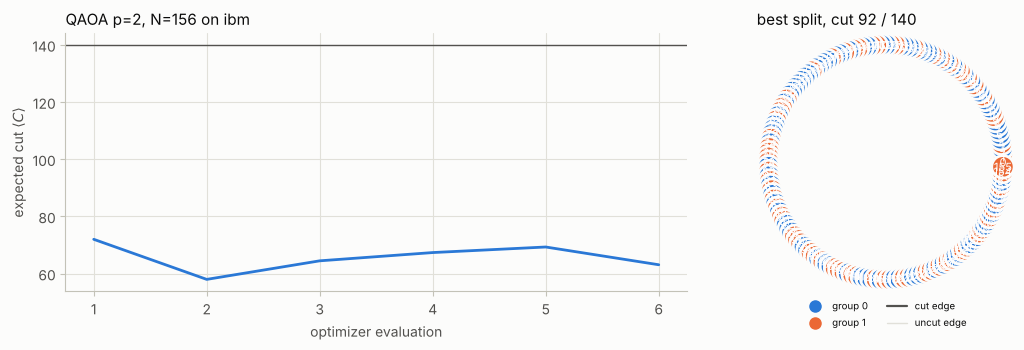

In [12]:
# ---------------------------------------------------------------------------------
# Section 10 - Final benchmark report
# ---------------------------------------------------------------------------------
if not execution_ok:
    print(f"No report: execution failed with {type(execution_error).__name__}: {execution_error}")
else:
    phases_report = dict(phases)
    phases_report["execution_s"] = phases["execution_s"] + later_launch_time if phases["execution_s"] is not None else None
    report = build_report("QAOA (Max-Cut)", backend_cfg, N_QUBITS, SHOTS, phases_report, memory,
                          extra_times={"Final sampling run": sampling_time,
                                       "Classical optimizer + Python overhead": optimisation_time - later_launch_time
                                       - (phases["wall_s"] if phases["wall_s"] else 0)})
    report["Graph"] = f"{graph_kind}: {N_QUBITS} nodes, {len(edges)} edges, total weight {total_weight:g}"
    report["QAOA depth p / optimizer"] = f"{QAOA_LAYERS} / {OPTIMIZER} ({len(history_cut)} evaluations)"
    report["Expected result"] = f"max cut = {max_cut:g} ({reference_kind})"
    report["Actual result"] = f"best sampled cut = {best_sample[2]:g} ({best_sample[0]}); <C> = {expected_cut:.4f}"
    report["Approximation ratio <C>/Cmax"] = f"{ratio:.4f}"
    report["Best sampled cut / Cmax"] = f"{best_sample[2] / max_cut:.4f}"
    report["P(sampling an optimal split)"] = f"{optimal_hits / SHOTS:.4f}"
    final_fig, (fa, fb) = plt.subplots(1, 2, figsize=(11, 3.6), gridspec_kw={"width_ratios": [1.6, 1]})
    fa.plot(np.arange(1, len(history_cut) + 1), history_cut, color=BLUE)
    fa.axhline(max_cut, color=INK_SECONDARY, linewidth=1)
    fa.set_xlabel("optimizer evaluation")
    fa.set_ylabel(r"expected cut $\langle C\rangle$")
    fa.set_title(f"QAOA p={QAOA_LAYERS}, N={N_QUBITS} on {cudaq.get_target().name}", loc="left")
    draw_graph(fb, split=best_sample[0], title=f"best split, cut {best_sample[2]:g} / {max_cut:g}")
    final_fig.tight_layout()
    show_report(report, save=SAVE_REPORT, out_dir=EXPORT_DIR, name="qaoa_benchmark_report", figure=final_fig)
    plt.show()

---
### Things to try next
* Increase `QAOA_LAYERS` to 3-4 (and `MAX_EVALUATIONS` to ~200): the approximation ratio usually improves.
* Set `OBJECTIVE_SHOTS = 1000` to optimise with shot noise, as on real hardware, and compare the convergence curve.
* `N_QUBITS = 24-30` with `BACKEND = "gpu"`: every optimizer evaluation is a full state-vector simulation, so the
  saved reports show how GPU execution time scales with the number of qubits and edges.